# GNN para estações meteorológicas — grafo v0.8.0 (PyTorch Geometric)

Versão evoluída do `grafo-0.7.5-pyg.ipynb`, com seleção automática de dispositivo
para **CUDA**, **MPS/Metal (Apple Silicon)** e CPU.

## Novidades desta versão (0.8.0)

1. **Normalização das arestas por nó de destino** (substitui a normalização
   global min-max). Garante que a soma dos pesos dos vizinhos que chegam a cada
   nó seja 1 — equivalente a `D^{-1} A` (normalização por linha).
2. **Feature Propagation iterativa nos nós cegos** (Rossi et al., ICLR 2022),
   substituindo a imputação por média simples dos vizinhos. Minimiza a energia
   de Dirichlet via difusão com adjacência simétrica `D^{-1/2} A D^{-1/2}` e
   restauração das âncoras a cada iteração (40 iterações).
3. **Identificação de anomalias** com duas regras: (R1) limiar meteorológico
   previsto por estação/mês/variável (percentil 95) com janela anti-ruído de 3
   timesteps, e (R2) *anomaly score* multivariado via distância de Mahalanobis.
4. **Exportação de artefatos** para o `dashboard.py` (Streamlit + Plotly).


In [1]:
import os
import re
import glob
import math
import pickle
import unicodedata
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx

from torch_geometric.data import Data
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import scatter


def selecionar_dispositivo():
    """Seleciona automaticamente CUDA, depois MPS (Apple Silicon), senão CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda"), "cuda"
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps"), "mps"
    return torch.device("cpu"), "cpu"


DEVICE, BACKEND = selecionar_dispositivo()

# Pasta onde os artefatos para o dashboard serão salvos.
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Backend:", BACKEND)
print("Artifacts dir:", os.path.abspath(ARTIFACTS_DIR))

Device: cuda
Backend: cuda
Artifacts dir: /home/viniz0r/backup_GNN_2026-07-07/paper_essenciais/codigo/artifacts


## 1. Carregamento do grafo


In [2]:
G = nx.read_graphml("002.graphml", force_multigraph=True)

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))
print("Primeiros nós:", list(G.nodes())[:10])


Grafo com 35 nós e 85 arestas. Direcionado: False
Primeiros nós: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 2. Funções auxiliares geográficas e visualização do grafo


Coordenadas carregadas para 35 nós.
Exemplos:
  Nó  0: (-23.43640996621655, -46.90925768439525)
  Nó 19: (-23.546111111111113, -46.63194444444444)
  Nó 33: (-23.64, -46.6175)
  Nó 34: (-23.496111111111112, -46.61972222222222)

Todos os nós têm coordenadas explícitas. ✅

Pesos geográficos calculados para 85 arestas.
  Distância mín : 0.1000 km
  Distância máx : 28.6249 km
  Peso mín      : 0.034935  (nós mais distantes)
  Peso máx      : 10.000000  (nós mais próximos)
  Peso médio    : 0.272973

Amostra de arestas com distância e peso usados no grafo:
  0 -> 1: distância = 18.8461 km | peso = 0.053061
  0 -> 17: distância = 22.9402 km | peso = 0.043592
  0 -> 27: distância = 17.2435 km | peso = 0.057993
  1 -> 2: distância = 3.8313 km | peso = 0.261006
  1 -> 17: distância = 5.6029 km | peso = 0.178478


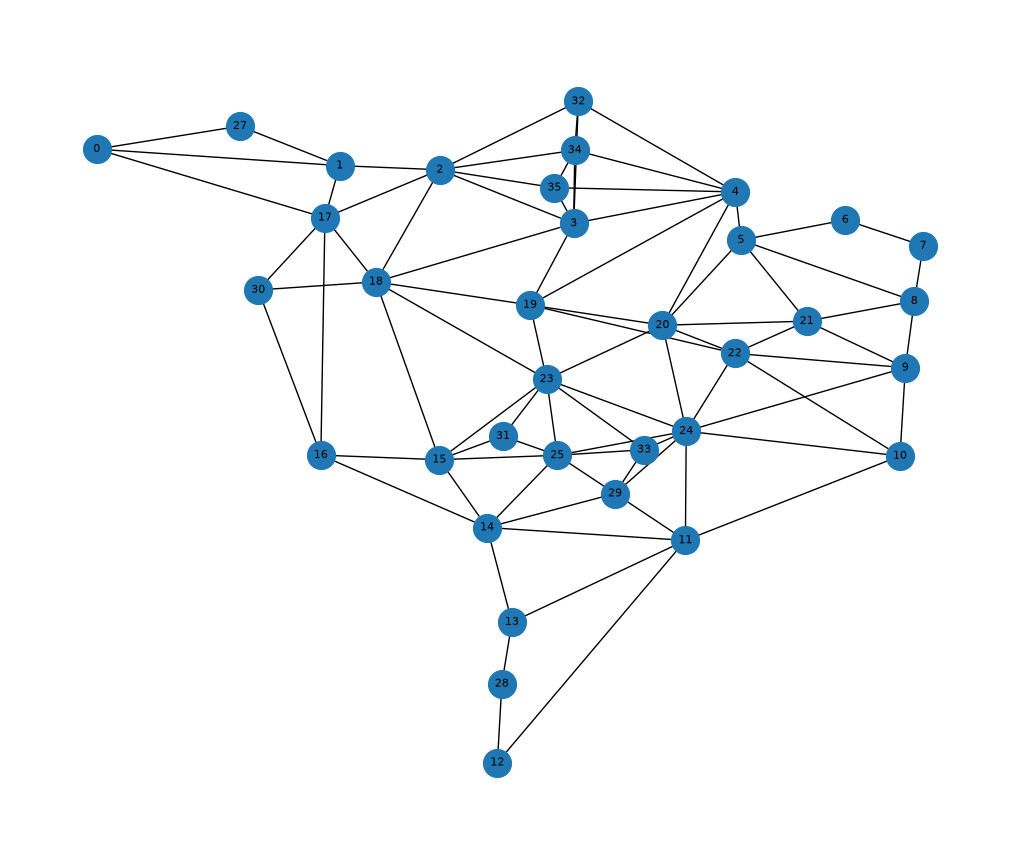

In [3]:
def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = float(degrees) + float(minutes) / 60 + float(seconds) / 3600
    if str(direction).upper() in ["S", "W", "O"]:
        decimal *= -1
    return decimal


def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c


# Coordenadas de todas as estações
# Formato DMS: (graus, min, seg, direção) para lat e lon
_COORDS_DMS = {
    '1':  (23, 28, 46, 'S', 46, 43, 50, 'W'),
    '2':  (23, 29, 13, 'S', 46, 41, 38, 'W'),
    '3':  (23, 28, 38, 'S', 46, 36, 26, 'W'),
    '4':  (23, 30, 33, 'S', 46, 36, 26, 'W'),
    '5':  (23, 31, 16, 'S', 46, 31, 24, 'W'),
    '6':  (23, 30, 10, 'S', 46, 26, 21, 'W'),
    '7':  (23, 30, 12, 'S', 46, 23, 10, 'W'),
    '8':  (23, 32,  6, 'S', 46, 27, 16, 'W'),
    '9':  (23, 36,  0, 'S', 46, 28, 50, 'W'),
    '10': (23, 40,  4, 'S', 46, 27, 39, 'W'),
    '11': (23, 46, 44, 'S', 46, 31, 42, 'W'),
    '12': (23, 56, 11, 'S', 46, 42, 31, 'W'),
    '13': (23, 40, 58, 'S', 46, 42, 41, 'W'),
    '14': (23, 35, 16, 'S', 46, 43,  0, 'W'),
    '15': (23, 41, 19, 'S', 46, 46, 14, 'W'),
    '16': (23, 37, 58, 'S', 46, 45, 58, 'W'),
    '17': (23, 31, 28, 'S', 46, 42, 21, 'W'),
    '18': (23, 33, 57, 'S', 46, 41, 22, 'W'),
    '19': (23, 32, 46, 'S', 46, 37, 55, 'W'),
    '20': (23, 33, 46, 'S', 46, 35, 52, 'W'),
    '21': (23, 34,  7, 'S', 46, 32, 49, 'W'),
    '22': (23, 35, 33, 'S', 46, 34, 26, 'W'),
    '23': (23, 35, 18, 'S', 46, 38,  4, 'W'),
    '24': (23, 35, 20, 'S', 46, 36, 19, 'W'),
    '25': (23, 39,  8, 'S', 46, 38, 51, 'W'),
    '27': (23, 24, 35, 'S', 46, 44, 34, 'W'),
    '28': (23, 49, 31, 'S', 46, 42, 20, 'W'),
    '29': (23, 40, 30, 'S', 46, 39, 17, 'W'),
    '30': (23, 34,  8, 'S', 46, 43, 45, 'W'),
    '31': (23, 38, 33, 'S', 46, 41, 58, 'W'),
    '32': (23, 24, 44, 'S', 46, 35, 14, 'W'),
    '34': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '35': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '33': (23, 38, 24, 'S', 46, 37, 3, 'W')
}

_COORDS_DEC = {
   # '33': (-23.559765113146554, -46.73399418127595),
    '0':  (-23.43640996621655,  -46.90925768439525),
}

COORDS = {}
for node, dms in _COORDS_DMS.items():
    lat = dms_to_decimal(dms[0], dms[1], dms[2], dms[3])
    lon = dms_to_decimal(dms[4], dms[5], dms[6], dms[7])
    COORDS[node] = (lat, lon)
for node, dec in _COORDS_DEC.items():
    COORDS[node] = dec

print(f"Coordenadas carregadas para {len(COORDS)} nós.")
print("Exemplos:")
for n in ['0', '19', '33', '34']:
    if n in COORDS:
        print(f"  Nó {n:>2}: {COORDS[n]}")

nos_sem_coordenada = []
for node in G.nodes():
    node_str = str(node)
    if node_str in COORDS:
        G.nodes[node]['lat'] = COORDS[node_str][0]
        G.nodes[node]['lon'] = COORDS[node_str][1]
    else:
        try:
            G.nodes[node]['lat'] = float(G.nodes[node].get('y', 0))
            G.nodes[node]['lon'] = float(G.nodes[node].get('x', 0))
        except (ValueError, TypeError):
            G.nodes[node]['lat'] = 0.0
            G.nodes[node]['lon'] = 0.0
        nos_sem_coordenada.append(node)

if nos_sem_coordenada:
    print(f"\n[AVISO] Nós sem coordenada explícita (usou fallback x/y): {nos_sem_coordenada}")
else:
    print("\nTodos os nós têm coordenadas explícitas. ✅")

# Peso geográfico das arestas:
# - edge_distance_km: distância haversine em quilômetros
# - inverse_distance_weight: 1 / distância_km
# A GNN usa inverse_distance_weight como edge_weight, ou seja,
# vizinhos mais próximos influenciam mais a mensagem propagada.
DIST_MIN_KM = 0.1

for u, v, k in G.edges(keys=True):
    lat_u = G.nodes[u].get('lat', 0.0)
    lon_u = G.nodes[u].get('lon', 0.0)
    lat_v = G.nodes[v].get('lat', 0.0)
    lon_v = G.nodes[v].get('lon', 0.0)

    dist_km = haversine(lat_u, lon_u, lat_v, lon_v)
    dist_km = max(dist_km, DIST_MIN_KM)
    inv_dist = 1.0 / dist_km

    G.edges[u, v, k]['edge_distance_km'] = dist_km
    G.edges[u, v, k]['inverse_distance_weight'] = inv_dist
    G.edges[u, v, k]['weight'] = inv_dist

pesos = [d['weight'] for _, _, d in G.edges(data=True)]
distancias = [d['edge_distance_km'] for _, _, d in G.edges(data=True)]
print(f"\nPesos geográficos calculados para {len(pesos)} arestas.")
print(f"  Distância mín : {min(distancias):.4f} km")
print(f"  Distância máx : {max(distancias):.4f} km")
print(f"  Peso mín      : {min(pesos):.6f}  (nós mais distantes)")
print(f"  Peso máx      : {max(pesos):.6f}  (nós mais próximos)")
print(f"  Peso médio    : {sum(pesos)/len(pesos):.6f}")

print("\nAmostra de arestas com distância e peso usados no grafo:")
for idx, (u, v, d) in enumerate(G.edges(data=True)):
    print(
        f"  {u} -> {v}: distância = {d['edge_distance_km']:.4f} km | "
        f"peso = {d['weight']:.6f}"
    )
    if idx >= 4:
        break

pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=400, font_size=8)
plt.title("Grafo das estações (peso = 1 / distância haversine)")
plt.show()
plt.close()


## 3. Caminhos dos dados e carregamento bruto dos CSVs


In [4]:
PATH_2023 = "/home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2023"
PATH_2024 = "/home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2024"


def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","


def _corrigir_cabecalho_csv_cge(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linhas = f.readlines()

    if not linhas:
        return ""

    cabecalho_original = linhas[0]
    cabecalho_corrigido = cabecalho_original.replace("DATA,,", "DATA,", 1)
    cabecalho_corrigido = cabecalho_corrigido.replace("data,,", "data,", 1)
    linhas[0] = cabecalho_corrigido
    return "".join(linhas)


def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []
    arquivos_com_cabecalho_corrigido = 0

    print(f"Iniciando processamento de {len(arquivos)} arquivos em {path}")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")
        sep = _detectar_sep(arq)

        if sep == ",":
            with open(arq, "r", encoding="utf-8", errors="ignore") as f:
                primeira_linha = f.readline()
            if "DATA,," in primeira_linha or "data,," in primeira_linha:
                arquivos_com_cabecalho_corrigido += 1

            conteudo_csv = _corrigir_cabecalho_csv_cge(arq)
            df = pd.read_csv(
                __import__("io").StringIO(conteudo_csv),
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )
        else:
            df = pd.read_csv(
                arq,
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )

        df.columns = [c.strip() for c in df.columns]

        if "DATA" not in df.columns:
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        # A correção deve acontecer ANTES do read_csv, nunca por reposicionamento
        # posterior das colunas. Se esta coluna aparecer, o cabeçalho ainda veio quebrado.
        if "Unnamed: 2" in df.columns:
            raise ValueError(
                f"Falha ao corrigir cabeçalho do CGE em {os.path.basename(arq)}. "
                "A coluna vazia 'Unnamed: 2' ainda existe após a leitura."
            )

        # A versão 1.6.2 aceitava múltiplos formatos e por isso mantinha janeiro completo.
        # Aqui retomamos esse comportamento para evitar o corte por parsing após 13/01.
        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", format="mixed", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()
        df = df[~df.index.duplicated(keep="first")]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                    .str.replace(",", ".", regex=False)
                    .str.strip()
                )
                try:
                    df[col] = pd.to_numeric(df[col], errors="ignore")
                except Exception:
                    pass

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    if not estacoes_processadas:
        raise ValueError(f"Nenhum CSV encontrado em {path}")

    print(f"Arquivos com cabeçalho CGE corrigido em {path}: {arquivos_com_cabecalho_corrigido}")

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final


df_2023 = carregar_estacoes_sem_agregar(PATH_2023)
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

print(f"Total de registros 2023: {len(df_2023)}")
print(f"Total de registros 2024: {len(df_2024)}")
print("Colunas 2023:", df_2023.columns.tolist())
print("Colunas 2024:", df_2024.columns.tolist())
print("Período 2024 carregado:", df_2024.index.min(), "até", df_2024.index.max())

try:
    temp_preview_2024 = pd.to_numeric(df_2024["Temp(oC)"], errors="coerce")
    print(
        "Prévia Temp(oC) 2024:",
        f"média={temp_preview_2024.mean():.3f}",
        f"mín={temp_preview_2024.min():.3f}",
        f"máx={temp_preview_2024.max():.3f}"
    )
except Exception as e:
    print("Não foi possível gerar prévia de Temp(oC) 2024:", e)


Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2023
Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2023: 32
Iniciando processamento de 32 arquivos em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2024
Arquivos com cabeçalho CGE corrigido em /home/viniz0r/backup_GNN_2026-07-07/completo/estações_meteorológicas/meteorologicas_2024: 32
Total de registros 2023: 1730836
Total de registros 2024: 1676382
Colunas 2023: ['Posto', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Rajada.VT(m/s)', 'station_id', 'PressÃ£o(mb)', 'Sens. Térmica(°C)']
Colunas 2024: ['Posto', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Rajada.VT(m/s)', 'station_id', 'PressÃ£o(mb)', 'Sens. Térmica(°C)']
Período 2024 car

## 4. Montagem robusta do tensor `[tempo, nós, atributos]` com diagnóstico e imputação espacial dos nós cegos


In [5]:
def normalizar_nome(s):
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("ASCII")
    s = re.sub(r"[^a-z0-9]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s


MAPA_FIXO_CSV = {
    "p503": "19",
    "p510": "3",
    "p846": "14",
    "p1000857": "13",
    "p1000880": "0",
}

NOS_CEGOS_DEFAULT = {"33", "34", "35"}

_STOPWORDS_MATCH = {
    "do", "da", "de", "dos", "das", "e", "o", "a", "os", "as", "em", "no", "na",
    "sp", "cge", "dados", "pmsp", "comdec", "municipal", "meteorologica",
    "estacao", "esta", "paco", "rinco",
    "fo", "la", "sa", "cl", "mo", "mp", "iq", "vm", "pr", "pa", "bt", "pi",
    "ip", "sm", "mb", "af", "mg", "ad", "ja", "cs", "jt", "pe", "it", "pj", "vp",
}


def _palavras_relevantes(s):
    norm = normalizar_nome(s)
    tokens = norm.split("_")
    tokens = [t for t in tokens if not re.match(r"^p\d+$", t)]
    return [t for t in tokens if len(t) >= 3 and t not in _STOPWORDS_MATCH]


def _score_tokens(tokens_csv, tokens_label):
    if not tokens_label:
        return 0.0
    matches = sum(
        1 for pl in tokens_label
        if any(pl in pc or pc in pl for pc in tokens_csv)
    )
    return matches / len(tokens_label)


def construir_indice_mapeamento_nos(G):
    indice = []
    for node in G.nodes():
        label = G.nodes[node].get("label", "")
        indice.append({
            "node_id": str(node),
            "label": label,
            "tokens_label": _palavras_relevantes(label),
        })
    return indice


INDICE_NOS_PARA_MATCH = construir_indice_mapeamento_nos(G)


def encontrar_no_correspondente(nome_arquivo, indice_nos=INDICE_NOS_PARA_MATCH):
    stem_norm = normalizar_nome(nome_arquivo)

    for chave, node_id in MAPA_FIXO_CSV.items():
        if chave in stem_norm:
            return node_id

    tokens_csv = _palavras_relevantes(nome_arquivo)
    melhor_no = None
    melhor_score = 0.0

    for item in indice_nos:
        score = _score_tokens(tokens_csv, item["tokens_label"])
        if score > melhor_score:
            melhor_score = score
            melhor_no = item["node_id"]

    if melhor_score >= 0.5:
        return melhor_no

    return None


def mapear_estacoes_para_nos(station_ids_unicos):
    mapeamento = {}
    for station_id in sorted(set(map(str, station_ids_unicos))):
        mapeamento[station_id] = encontrar_no_correspondente(station_id)
    return mapeamento


def imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=NOS_CEGOS_DEFAULT):
    no_para_stations = {}
    for station_id, node_id in mapa_station_para_no.items():
        if node_id is None:
            continue
        no_para_stations.setdefault(str(node_id), []).append(station_id)

    print(f"\n[{nome_conjunto}] CSV associado a cada nó para treino:")
    for node in map(str, G.nodes()):
        label = G.nodes[node].get("label", "")
        csvs = sorted(no_para_stations.get(node, []))
        if csvs:
            print(f"  Nó {node:>2} ({label}): {', '.join(f'{csv}.csv' for csv in csvs)}")
        elif node in set(map(str, nos_cegos)):
            print(f"  Nó {node:>2} ({label}): nó cego -> sem CSV próprio, entrada via média simples dos vizinhos")
        else:
            print(f"  Nó {node:>2} ({label}): sem CSV associado")

    estacoes_sem_no = sorted([station for station, node in mapa_station_para_no.items() if node is None])
    if estacoes_sem_no:
        print(f"\n[{nome_conjunto}] Estações sem correspondência no grafo:")
        for est in estacoes_sem_no:
            print(f"  - {est}.csv")


def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    normalizadas = {normalizar_nome(c): c for c in df.columns}
    for c in candidatos:
        if c in df.columns:
            return c
    for c in candidatos:
        c_norm = normalizar_nome(c)
        if c_norm in normalizadas:
            return normalizadas[c_norm]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")


def _vizinhos_do_no(G, node):
    node = str(node)
    vizinhos = []

    for viz in G.neighbors(node):
        vizinhos.append(str(viz))

    if len(vizinhos) == 0:
        return []

    return vizinhos


def forcar_nos_cegos_sem_dados(df_pivot, nos_cegos, features):
    for feat in features:
        for no in map(str, nos_cegos):
            if no in df_pivot[feat].columns:
                df_pivot[(feat, no)] = np.nan
    return df_pivot


def imputar_nos_cegos_por_vizinhos(df_pivot, G, nos_cegos, features):
    for feat in features:
        bloco = df_pivot[feat].copy()

        for no in map(str, nos_cegos):
            if no not in bloco.columns:
                continue

            if not bloco[no].isna().all():
                continue

            vizinhos = [v for v in _vizinhos_do_no(G, no) if v in bloco.columns]

            if len(vizinhos) == 0:
                print(f"[IMPUTAÇÃO] Nó {no} sem vizinhos válidos para {feat}.")
                continue

            mat = bloco[vizinhos].to_numpy(dtype=float)
            imputado = np.full(shape=(mat.shape[0],), fill_value=np.nan, dtype=float)

            for t in range(mat.shape[0]):
                linha = mat[t]
                mask = ~np.isnan(linha)
                if mask.sum() == 0:
                    continue

                imputado[t] = float(np.mean(linha[mask]))

            bloco[no] = imputado
            print(f"[IMPUTAÇÃO] Nó cego {no} preenchido por média simples dos vizinhos em {feat}.")

        df_pivot[feat] = bloco

    return df_pivot


def inicializar_nos_cegos_zero(df_pivot, nos_cegos, features):
    """Inicializa os nós cegos com 0.0 (entrada do Feature Propagation)."""
    for feat in features:
        bloco = df_pivot[feat]
        for no in map(str, nos_cegos):
            if no in bloco.columns:
                df_pivot[(feat, no)] = 0.0
    return df_pivot


def preparar_dataset_final_v6(
    df_input: pd.DataFrame,
    G,
    nome_conjunto="dataset",
    nos_cegos=NOS_CEGOS_DEFAULT
):
    df_fix = df_input.copy()

    def _selecionar_coluna_temperatura(df: pd.DataFrame) -> str:
        candidatos = [
            "Temp(oC)",
            "Temp(°C)",
            "Temperatura(°C)",
            "Sens. Térmica(°C)",
            "Sens. Termica(°C)",
        ]
        normalizadas = {normalizar_nome(c): c for c in df.columns}
        disponiveis = []
        for cand in candidatos:
            if cand in df.columns:
                col = cand
            else:
                col = normalizadas.get(normalizar_nome(cand))
            if col is None:
                continue
            serie = pd.to_numeric(df[col], errors="coerce")
            disponiveis.append((col, int(serie.notna().sum())))

        if not disponiveis:
            raise KeyError("Nenhuma coluna de temperatura encontrada.")

        disponiveis.sort(key=lambda item: (-item[1], candidatos.index(item[0]) if item[0] in candidatos else 999))
        col_escolhida = disponiveis[0][0]
        if normalizar_nome(col_escolhida).startswith("sens_termica"):
            print(f"[AVISO] Usando sensação térmica como fallback de temperatura: {col_escolhida}")
        return col_escolhida

    col_plu = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "pluviosidade(mm)", "Pluviosidade(mm)"])
    col_vel = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    col_temp = _selecionar_coluna_temperatura(df_fix)

    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        try:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break
        except KeyError:
            continue

    print(f"\n[{nome_conjunto}] Colunas escolhidas:")
    print("PLU  ->", col_plu)
    print("TEMP ->", col_temp)
    print("UMID ->", col_umid if col_umid is not None else "não encontrada")
    print("VEL  ->", col_vel)

    df_fix["PLU_real"] = pd.to_numeric(df_fix[col_plu], errors="coerce")
    df_fix["VEL_real"] = pd.to_numeric(df_fix[col_vel], errors="coerce")
    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce") if col_umid is not None else np.nan

    station_ids_unicos = df_fix["station_id"].astype(str).dropna().unique().tolist()
    mapa_station_para_no = mapear_estacoes_para_nos(station_ids_unicos)
    df_fix["node_id"] = df_fix["station_id"].astype(str).map(mapa_station_para_no)

    imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=nos_cegos)

    print(f"\n[{nome_conjunto}] Total de linhas antes do dropna: {len(df_fix)}")
    sem_no = df_fix["node_id"].isna().sum()
    print(f"[{nome_conjunto}] Linhas sem node_id: {sem_no}")

    df_fix = df_fix.dropna(subset=["node_id"]).copy()
    df_fix["node_id"] = df_fix["node_id"].astype(str)

    features = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(map(str, G.nodes()))

    df_pivot = (
        df_fix.reset_index()
        .pivot_table(index="DATA", columns="node_id", values=features, aggfunc="mean")
        .sort_index()
    )

    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    # Mantém explicitamente 33, 34 e 35 como nós cegos no experimento,
    # mesmo que no futuro alguma fonte auxiliar apareça para eles.
    df_pivot = forcar_nos_cegos_sem_dados(df_pivot, nos_cegos=nos_cegos, features=features)

    for feat in features:
        bloco = df_pivot[feat]
        nos_vazios = bloco.columns[bloco.isna().all()].tolist()
        if nos_vazios:
            print(f"[ALERTA][{nome_conjunto}] Nós totalmente vazios para {feat}: {nos_vazios}")

    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    # MUDANÇA 2: os nós cegos NÃO são mais preenchidos por média simples dos
    # vizinhos aqui. Eles são inicializados em 0.0 e preenchidos depois, fora
    # desta função, pelo Feature Propagation iterativo (Rossi et al., 2022),
    # que usa a estrutura completa do grafo e restaura as âncoras a cada passo.
    df_pivot = inicializar_nos_cegos_zero(
        df_pivot=df_pivot,
        nos_cegos=nos_cegos,
        features=features
    )
    df_pivot = df_pivot.ffill().bfill()

    for feat in features:
        if feat == "PLU_real":
            df_pivot[feat] = df_pivot[feat].fillna(0.0)
        else:
            media_global = np.nanmean(df_pivot[feat].to_numpy(dtype=float))
            if np.isnan(media_global):
                media_global = 0.0
            df_pivot[feat] = df_pivot[feat].fillna(float(media_global))

    data_3d = (
        df_pivot.values
        .reshape(len(df_pivot), len(features), len(nodes_lista))
        .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d, dtype=torch.float32).to(DEVICE)
    return X, df_pivot.index, df_fix, df_pivot, mapa_station_para_no


X_2023, timestamps_2023, df_fix_2023, df_pivot_2023, mapa_csv_no_2023 = preparar_dataset_final_v6(df_2023, G, nome_conjunto="2023")
X_2024, timestamps_2024, df_fix_2024, df_pivot_2024, mapa_csv_no_2024 = preparar_dataset_final_v6(df_2024, G, nome_conjunto="2024")

print("\nShapes finais:")
print("X_2023:", X_2023.shape)
print("X_2024:", X_2024.shape)
print("Primeiros timestamps 2023:", list(timestamps_2023[:5]))
print("Primeiros timestamps 2024:", list(timestamps_2024[:5]))
print("Últimos timestamps 2024:", list(timestamps_2024[-5:]))



[2023] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Temp(oC)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)

[2023] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): dados_cge___P1000880_Santana_do_Parna_ba.csv
  Nó  1 (Pirituba): dados_cge___P515_Pirituba__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): dados_cge___P509_Freguesia_do____PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): dados_cge___P510_Santana_Tucuruvi___COMDEC__PMSP_ST_01_.csv
  Nó  4 (Vila Maria / Guilherme): dados_cge___P540_Vila_Maria___Vila_Guilherme__PMSP_MG_01_.csv
  Nó  5 (Penha): dados_cge___P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): dados_cge___P1000862_S_o_Miguel_Paulista__PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): dados_cge___P1000882_Itaim_Paulista__PMSP_IT_01_.csv
  Nó  8 (Itaquera): dados_cge___P1000864_Itaquera__PMSP_IQ_02_.csv
  Nó  9 (São Mateus): dados_cge___P1000844_S_o_Mateus__PMSP_SM_05_.csv
  Nó 10 (Mauá - Paço Municipal): dados_cge___P1000876_Mau____Pa_o_Municipal.

## 6. Grafo em PyTorch Geometric e teste rápido


## Mudança 1 — Normalização das arestas por nó de destino

**Problema da versão anterior (0.7.5):** o `edge_weight` era normalizado por
min-max global (`(w - w.min()) / (w.max() - w.min())`). Uma única aresta muito
curta (peso enorme) comprimia todos os outros pesos para perto de zero,
dominando a agregação.

**Correção:** normalização por **nó de destino**, garantindo que a soma dos
pesos das arestas que chegam a cada nó seja 1:

$$\tilde{w}_{ij} = \frac{w_{ij}}{\sum_{k \in N(j)} w_{kj}}$$

Em PyG isso corresponde à normalização $D^{-1} A$ (por linha do nó destino).
Também definimos a versão **simétrica** $D^{-1/2} A D^{-1/2}$, usada pelo
Feature Propagation (Mudança 2).


In [6]:
def normalize_edge_weights_by_destination(edge_index, edge_weight, num_nodes):
    """Normaliza w_ij dividindo pela soma dos pesos que chegam ao nó destino j.

    Equivale a D^{-1} A (normalização por linha do nó de destino), garantindo
    que sum_{k in N(j)} w_kj = 1 para todo j com pelo menos um vizinho.
    edge_index: [2, E] (linha 0 = origem i, linha 1 = destino j)
    """
    dst = edge_index[1]
    deg = scatter(edge_weight, dst, dim=0, dim_size=num_nodes, reduce="sum")
    deg = deg.clamp(min=1e-12)
    return edge_weight / deg[dst]


def normalize_edge_weights_symmetric(edge_index, edge_weight, num_nodes):
    """Normalização simétrica D^{-1/2} A D^{-1/2}, usada no Feature Propagation."""
    src, dst = edge_index[0], edge_index[1]
    deg = scatter(edge_weight, dst, dim=0, dim_size=num_nodes, reduce="sum")
    deg = deg.clamp(min=1e-12)
    deg_inv_sqrt = deg.pow(-0.5)
    return deg_inv_sqrt[src] * edge_weight * deg_inv_sqrt[dst]


In [7]:
# PyTorch Geometric trabalha com edge_index.
# Se o grafo for não-direcionado, duplicamos cada aresta nos dois sentidos.
nodes_lista = list(G.nodes())
node_to_idx = {node: i for i, node in enumerate(nodes_lista)}

edges_src = []
edges_dst = []
edges_weight_raw = []
edges_distance_km = []

for u, v, attrs in G.edges(data=True):
    i = node_to_idx[u]
    j = node_to_idx[v]
    dist_km = float(attrs.get("edge_distance_km", 0.0))
    raw_weight = float(attrs.get("inverse_distance_weight", attrs.get("weight", 1.0)))

    edges_src.append(i)
    edges_dst.append(j)
    edges_weight_raw.append(raw_weight)
    edges_distance_km.append(dist_km)

    if not G.is_directed():
        edges_src.append(j)
        edges_dst.append(i)
        edges_weight_raw.append(raw_weight)
        edges_distance_km.append(dist_km)

edge_index = torch.tensor([edges_src, edges_dst], dtype=torch.long)
edge_weight_raw = torch.tensor(edges_weight_raw, dtype=torch.float32)
edge_distance_km = torch.tensor(edges_distance_km, dtype=torch.float32)

# MUDANÇA 1: normalização por nó de destino (D^{-1} A), no lugar do antigo
# min-max global. Garante que a soma dos pesos dos vizinhos de cada nó seja 1.
edge_weight = normalize_edge_weights_by_destination(
    edge_index, edge_weight_raw, num_nodes=len(nodes_lista)
)

# Versão simétrica D^{-1/2} A D^{-1/2}, reservada ao Feature Propagation (Mudança 2).
edge_weight_sym = normalize_edge_weights_symmetric(
    edge_index, edge_weight_raw, num_nodes=len(nodes_lista)
)

g_pyg = Data(
    edge_index=edge_index,
    edge_weight=edge_weight,
    edge_weight_sym=edge_weight_sym,
    edge_weight_raw=edge_weight_raw,
    edge_distance_km=edge_distance_km,
    num_nodes=len(nodes_lista)
).to(DEVICE)

print(f"Grafo PyG: {g_pyg.num_nodes} nós, {g_pyg.edge_index.size(1)} arestas direcionadas")
print("Pesos usados na GNN:")
print(
    f"  edge_distance_km - mín: {g_pyg.edge_distance_km.min():.4f} | "
    f"máx: {g_pyg.edge_distance_km.max():.4f}"
)
print(
    f"  edge_weight_raw (1/distância) - mín: {g_pyg.edge_weight_raw.min():.6f} | "
    f"máx: {g_pyg.edge_weight_raw.max():.6f}"
)
print(
    f"  edge_weight normalizado - mín: {g_pyg.edge_weight.min():.4f} | "
    f"máx: {g_pyg.edge_weight.max():.4f} | "
    f"médio: {g_pyg.edge_weight.mean():.4f}"
)

print("\nAmostra PyG: distância geográfica versus peso efetivo")
for idx in range(min(5, g_pyg.edge_index.size(1))):
    src_idx = int(g_pyg.edge_index[0, idx].item())
    dst_idx = int(g_pyg.edge_index[1, idx].item())
    src_node = nodes_lista[src_idx]
    dst_node = nodes_lista[dst_idx]
    print(
        f"  {src_node} -> {dst_node}: distância = {g_pyg.edge_distance_km[idx].item():.4f} km | "
        f"peso bruto = {g_pyg.edge_weight_raw[idx].item():.6f} | "
        f"peso normalizado = {g_pyg.edge_weight[idx].item():.6f}"
    )


Grafo PyG: 35 nós, 170 arestas direcionadas
Pesos usados na GNN:
  edge_distance_km - mín: 0.1000 | máx: 28.6249
  edge_weight_raw (1/distância) - mín: 0.034935 | máx: 10.000000
  edge_weight normalizado - mín: 0.0091 | máx: 0.9045 | médio: 0.2059

Amostra PyG: distância geográfica versus peso efetivo
  0 -> 1: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.085597
  1 -> 0: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.343115
  0 -> 17: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.047756
  17 -> 0: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.281881
  0 -> 27: distância = 17.2435 km | peso bruto = 0.057993 | peso normalizado = 0.312895


## Mudança 2 — Feature Propagation iterativa nos nós cegos

Substitui a antiga imputação por média simples dos vizinhos (equivalente a uma
única iteração de difusão, sem restauração de âncoras).

Baseado em **Rossi et al., *On the Unreasonable Effectiveness of Feature
Propagation in Learning on Graphs With Missing Node Features*, ICLR 2022**.
O algoritmo minimiza a energia de Dirichlet
$\ell(x, G) = \tfrac{1}{2} x^\top \Delta x = \tfrac{1}{2} \sum_{ij}\tilde a_{ij}(x_i - x_j)^2$
propagando as features pela adjacência simétrica normalizada
$\tilde A = D^{-1/2} A D^{-1/2}$ e **restaurando os valores reais das âncoras a
cada iteração** (passo crítico). Usamos **40 iterações**.

Aplicamos a propagação independentemente a cada timestep dos tensores
`X_2023` e `X_2024`, preenchendo apenas os nós cegos (33, 34, 35); os nós CGE
(âncoras) permanecem com seus valores observados.


In [8]:
def feature_propagation_batch(X, edge_index, edge_weight, known_mask, num_iter=40):
    """Feature Propagation vetorizado sobre [T, N, F] (Rossi et al., ICLR 2022).

    Processa todos os timesteps em paralelo (sem loop por t).
    A cada iteração:
      1. X[:, dst, :] = sum_over_src( edge_weight * X[:, src, :] )   (difusão)
      2. X[:, known_mask, :] = X_known                                 (restaura âncoras)
    """
    X = X.clone().float()
    X_known = X[:, known_mask, :].clone()
    src, dst = edge_index[0], edge_index[1]
    ew = edge_weight.float().view(1, -1, 1)  # [1, E, 1] para broadcast
    T, N, F = X.shape

    for _ in range(num_iter):
        # [T, E, F] <- pesos dos vizinhos ponderados
        msgs = X[:, src, :] * ew                         # [T, E, F]
        # scatter: acumula msgs nos nós destino
        X_new = torch.zeros(T, N, F, device=X.device)
        X_new.index_add_(1, dst, msgs)
        X_new[:, known_mask, :] = X_known                # restaura âncoras
        X = X_new

    return X


def imputacao_media_vizinhos_batch(X, edge_index, num_nodes, blind_idx):
    """Baseline vetorizado: média simples dos vizinhos (1 passo), shape [T, N, F]."""
    X = X.clone().float()
    src, dst = edge_index[0], edge_index[1]
    T, N, F = X.shape
    # Contagem de vizinhos por nó destino
    cont = torch.zeros(N, device=X.device)
    cont.index_add_(0, dst, torch.ones(dst.size(0), device=X.device))
    cont = cont.clamp(min=1.0).view(1, N, 1)             # [1, N, 1]
    # Somar features dos vizinhos
    soma = torch.zeros(T, N, F, device=X.device)
    soma.index_add_(1, dst, X[:, src, :])
    media = soma / cont                                    # [T, N, F]
    # Aplicar apenas nos nós cegos
    blind_t = torch.tensor(blind_idx, device=X.device)
    X[:, blind_t, :] = media[:, blind_t, :]
    return X


# Conjunto de nós cegos (sem CSV próprio).
NOS_SEM_DADOS = {"33", "34", "35"}
known_mask = torch.tensor(
    [str(n) not in NOS_SEM_DADOS for n in nodes_lista],
    dtype=torch.bool, device=DEVICE
)
blind_idx = [i for i, n in enumerate(nodes_lista) if str(n) in NOS_SEM_DADOS]
print(f"Âncoras (known_mask=True): {int(known_mask.sum())} | "
      f"Nós cegos (False): {int((~known_mask).sum())} -> {sorted(NOS_SEM_DADOS)}")

FP_ITER = 40
ei  = g_pyg.edge_index.to(DEVICE)
ew_sym = g_pyg.edge_weight_sym.to(DEVICE)
# CORRECAO FP: usar normalizacao por linha D^{-1}A (random-walk) no Feature
# Propagation. A simetrica D^{-1/2}AD^{-1/2} encolhe o valor de nos cegos
# fracamente conectados em direcao a zero (undershoot); a row-stochastic da
# combinacao convexa dos vizinhos, mantendo a estimativa no intervalo fisico.
ew_rw = g_pyg.edge_weight.to(DEVICE)

# Baseline (1 passo, média simples) — salvo ANTES do FP para comparação.
print("Calculando baseline (média simples dos vizinhos)...")
X_2023_baseline = imputacao_media_vizinhos_batch(X_2023, ei, len(nodes_lista), blind_idx)
X_2024_baseline = imputacao_media_vizinhos_batch(X_2024, ei, len(nodes_lista), blind_idx)

# Feature Propagation vetorizado — processa todos os timesteps de uma vez.
print(f"Aplicando Feature Propagation ({FP_ITER} iterações) em X_2023...")
X_2023 = feature_propagation_batch(X_2023, ei, ew_rw, known_mask, num_iter=FP_ITER)
print(f"Aplicando Feature Propagation ({FP_ITER} iterações) em X_2024...")
X_2024 = feature_propagation_batch(X_2024, ei, ew_rw, known_mask, num_iter=FP_ITER)

print("Feature Propagation concluído.")
print("X_2023:", tuple(X_2023.shape), "| X_2024:", tuple(X_2024.shape))
for j in blind_idx:
    print(f"  Nó cego {nodes_lista[j]}: PLU médio FP = {X_2024[:, j, 0].mean():.4f} | "
          f"Temp média FP = {X_2024[:, j, 1].mean():.4f}")


Âncoras (known_mask=True): 32 | Nós cegos (False): 3 -> ['33', '34', '35']
Calculando baseline (média simples dos vizinhos)...
Aplicando Feature Propagation (40 iterações) em X_2023...
Aplicando Feature Propagation (40 iterações) em X_2024...
Feature Propagation concluído.
X_2023: (105141, 35, 4) | X_2024: (105292, 35, 4)
  Nó cego 33: PLU médio FP = 1.9685 | Temp média FP = 20.8377
  Nó cego 34: PLU médio FP = 2.0346 | Temp média FP = 20.9839
  Nó cego 35: PLU médio FP = 2.0278 | Temp média FP = 20.9877


## 5. Separação treino/teste para pluviosidade e temperatura (nó 33 cego, com imputação espacial)


In [9]:
TARGET_IDX_PLU  = 0
TARGET_IDX_TEMP = 1

# Nós que NÃO têm CSV: participam da agregação GraphSAGE mas são
# excluídos do cálculo de loss durante o treino.
# O modelo aprende a prever eles via vizinhos — e só depois comparamos
# com dados reais do INMET/USP.
NOS_SEM_DADOS = {"33", "34", "35"}   # USP, INMET automático, INMET convencional

nodes_lista = list(G.nodes())

# Índices (posição no tensor) dos nós COM dados — usados para mascarar o loss
IDX_TREINO = torch.tensor(
    [i for i, n in enumerate(nodes_lista) if str(n) not in NOS_SEM_DADOS],
    dtype=torch.long
)
print(f"Nós no treino (com dados): {len(IDX_TREINO)} de {len(nodes_lista)}")
print(f"Nós mascarados (sem CSV) : {NOS_SEM_DADOS}")

# ── chuva ────────────────────────────────────────────────────────────────────
Y_2023      = X_2023[1:, :, TARGET_IDX_PLU]
X_2023_final = X_2023[:-1, :, :]
Y_2024      = X_2024[1:, :, TARGET_IDX_PLU]
X_2024_final = X_2024[:-1, :, :]

X_train, Y_train = X_2023_final, Y_2023
X_test,  Y_test  = X_2024_final, Y_2024

# ── temperatura ──────────────────────────────────────────────────────────────
Y_2023_temp  = X_2023[1:, :, TARGET_IDX_TEMP]
X_2023_temp  = X_2023[:-1, :, :]
Y_2024_temp  = X_2024[1:, :, TARGET_IDX_TEMP]
X_2024_temp  = X_2024[:-1, :, :]

X_train_temp, Y_train_temp = X_2023_temp, Y_2023_temp
X_test_temp,  Y_test_temp  = X_2024_temp, Y_2024_temp

print("\nChuva:")
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "| Y_test :", Y_test.shape)
print("\nTemperatura:")
print("X_train_temp:", X_train_temp.shape, "| Y_train_temp:", Y_train_temp.shape)
print("X_test_temp :", X_test_temp.shape,  "| Y_test_temp :", Y_test_temp.shape)

print("Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.")


Nós no treino (com dados): 32 de 35
Nós mascarados (sem CSV) : {'33', '34', '35'}

Chuva:
X_train: torch.Size([105140, 35, 4]) | Y_train: torch.Size([105140, 35])
X_test : torch.Size([105291, 35, 4]) | Y_test : torch.Size([105291, 35])

Temperatura:
X_train_temp: torch.Size([105140, 35, 4]) | Y_train_temp: torch.Size([105140, 35])
X_test_temp : torch.Size([105291, 35, 4]) | Y_test_temp : torch.Size([105291, 35])
Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.


## 7. Modelo GraphSAGE


In [10]:
class WeightedSAGEConv(MessagePassing):
    """
    Versão simples de GraphSAGE com agregação média ponderada por edge_weight.
    A atualização segue a ideia:
        h'_i = W_self * x_i + W_neigh * mean_j( w_ij * x_j )
    """
    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="add")
        self.lin_self = nn.Linear(in_channels, out_channels)
        self.lin_neigh = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index, edge_weight=None):
        if edge_weight is None:
            edge_weight = torch.ones(
                edge_index.size(1),
                device=x.device,
                dtype=x.dtype
            )
        else:
            edge_weight = edge_weight.to(device=x.device, dtype=x.dtype)

        row, col = edge_index
        deg = torch.zeros(x.size(0), device=x.device, dtype=x.dtype)
        deg.index_add_(0, col, edge_weight)  # Ensure distance weights sum for the target node
        deg = deg.clamp(min=1e-8)

        neigh_agg = self.propagate(edge_index, x=x, edge_weight=edge_weight)
        neigh_mean = neigh_agg / deg.unsqueeze(-1)

        out = self.lin_self(x) + self.lin_neigh(neigh_mean)
        return out

    def message(self, x_j, edge_weight):
        return edge_weight.view(-1, 1) * x_j


class MeteorologiaGNN(nn.Module):
    """
    Modelo no ecossistema PyTorch Geometric.
    Mantém a ideia do GraphSAGE de 2 camadas e usa edge_weight
    na agregação ponderada pelos pesos haversine normalizados.
    """
    def __init__(self, in_feats, h_feats):
        super().__init__()
        self.conv1 = WeightedSAGEConv(in_feats, h_feats)
        self.conv2 = WeightedSAGEConv(h_feats, 1)

    def forward(self, data, in_feat):
        x = in_feat.to(DEVICE)
        edge_index = data.edge_index
        edge_weight = data.edge_weight

        h = self.conv1(x, edge_index, edge_weight)
        h = F.relu(h)
        h = self.conv2(h, edge_index, edge_weight)
        return h.squeeze(-1)


print(MeteorologiaGNN(in_feats=4, h_feats=32))

# Teste rápido de passagem
primeira_hora = X_train[0].to(DEVICE)
modelo_teste = MeteorologiaGNN(in_feats=4, h_feats=16).to(DEVICE)
saida = modelo_teste(g_pyg, primeira_hora)
print("\nTeste de passagem:")
print("  Entrada:", primeira_hora.shape)
print("  Saída  :", saida.shape)


MeteorologiaGNN(
  (conv1): WeightedSAGEConv()
  (conv2): WeightedSAGEConv()
)

Teste de passagem:
  Entrada: torch.Size([35, 4])
  Saída  : torch.Size([35])


## 8. Função única de treino


In [11]:
def treinar_modelo(
    X_train,
    Y_train,
    g_pyg,
    idx_treino,          # tensor de índices dos nós com dados reais
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="modelo"
):
    """
    Treina o modelo mascarando nós sem CSV no cálculo do loss.
    Os nós mascarados (33, 34, 35) recebem previsão via agregação dos vizinhos,
    mas seus erros NÃO penalizam o gradiente.
    """
    modelo = MeteorologiaGNN(in_feats=in_feats, h_feats=h_feats).to(DEVICE)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterion = nn.MSELoss()

    idx = idx_treino.to(DEVICE)

    best_loss = float("inf")
    no_improve = 0
    best_state = None
    historico_loss = []

    modelo.train()
    for epoch in range(1, max_epochs + 1):
        total_loss = 0.0

        for i in range(len(X_train)):
            x_i = X_train[i].to(DEVICE)
            y_i = Y_train[i].to(DEVICE)

            pred = modelo(g_pyg, x_i)           # shape [n_nos]
            loss = criterion(pred[idx], y_i[idx])

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        epoch_loss = total_loss / len(X_train)
        historico_loss.append(epoch_loss)
        print(f"{nome_modelo} | Época {epoch:4d} | Erro treino: {epoch_loss:.8f}")

        if epoch_loss <= target_loss:
            print(f"{nome_modelo} | Parando: erro <= {target_loss} (erro={epoch_loss:.8f})")
            best_state = deepcopy(modelo.state_dict())
            break

        if best_loss - epoch_loss > min_delta:
            best_loss = epoch_loss
            no_improve = 0
            best_state = deepcopy(modelo.state_dict())
        else:
            no_improve += 1
            if no_improve >= patience:
                print(
                    f"{nome_modelo} | Parando: melhora < {min_delta} por {patience} épocas. "
                    f"best={best_loss:.8f}, atual={epoch_loss:.8f}"
                )
                break

    if best_state is not None:
        modelo.load_state_dict(best_state)

    return modelo, historico_loss


## 9. Treino do modelo de pluviosidade


In [12]:
modelo, historico_loss = treinar_modelo(
    X_train=X_train,
    Y_train=Y_train,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=50,
    target_loss=1e-4,
    min_delta=1e-4,
    patience=2,
    nome_modelo="Pluviosidade"
)

Pluviosidade | Época    1 | Erro treino: 1.16702652
Pluviosidade | Época    2 | Erro treino: 0.50050288
Pluviosidade | Época    3 | Erro treino: 0.49005820
Pluviosidade | Época    4 | Erro treino: 0.48653134
Pluviosidade | Época    5 | Erro treino: 0.48506690
Pluviosidade | Época    6 | Erro treino: 0.48427486
Pluviosidade | Época    7 | Erro treino: 0.48383447
Pluviosidade | Época    8 | Erro treino: 0.48350193
Pluviosidade | Época    9 | Erro treino: 0.48328754
Pluviosidade | Época   10 | Erro treino: 0.48318597
Pluviosidade | Época   11 | Erro treino: 0.48314258
Pluviosidade | Época   12 | Erro treino: 0.48312967
Pluviosidade | Parando: melhora < 0.0001 por 2 épocas. best=0.48318597, atual=0.48312967


## 10. Treino do modelo de temperatura


In [13]:
modelo_temp, historico_loss_temp = treinar_modelo(
    X_train=X_train_temp,
    Y_train=Y_train_temp,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=50,
    target_loss=1e-4,
    min_delta=1e-4,
    patience=2,
    nome_modelo="Temperatura"
)

Temperatura | Época    1 | Erro treino: 0.18218412
Temperatura | Época    2 | Erro treino: 0.04656536
Temperatura | Época    3 | Erro treino: 0.04471299
Temperatura | Época    4 | Erro treino: 0.04437380
Temperatura | Época    5 | Erro treino: 0.04407788
Temperatura | Época    6 | Erro treino: 0.04405576
Temperatura | Época    7 | Erro treino: 0.04425791
Temperatura | Parando: melhora < 0.0001 por 2 épocas. best=0.04407788, atual=0.04425791


## 12. Função única para avaliar e plotar todos os nós


In [14]:
def avaliar_e_plotar_todos_nos(
    modelo,
    g_pyg,
    X_test,
    Y_test,
    timestamps_2024,
    nome_variavel="Chuva",
    ylabel="Valor",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=True,
    pasta_saida="graficos"
):
    modelo.eval()
    half_window = window // 2

    preds_all = []
    trues_all = []

    with torch.no_grad():
        for i in range(len(X_test)):
            pred = modelo(g_pyg, X_test[i])

            y_pred = pred.detach().cpu().numpy().reshape(-1)
            y_true = Y_test[i].detach().cpu().numpy().reshape(-1)

            preds_all.append(y_pred)
            trues_all.append(y_true)

    preds_all = np.array(preds_all)
    trues_all = np.array(trues_all)

    num_nos = preds_all.shape[1]
    tempo_2024 = np.array(timestamps_2024[1:])
    resultados = []

    pasta_variavel = os.path.join(pasta_saida, nome_variavel.lower().replace(" ", "_"))
    if salvar:
        os.makedirs(pasta_variavel, exist_ok=True)

    for node_id in range(num_nos):
        preds_no = preds_all[:, node_id]
        trues_no = trues_all[:, node_id]

        if criterio_janela == "pico_real":
            idx_central = int(np.argmax(trues_no))
        elif criterio_janela == "maior_desvio_media":
            idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))
        else:
            raise ValueError("criterio_janela deve ser 'pico_real' ou 'maior_desvio_media'")

        start = max(0, idx_central - half_window)
        end = min(len(trues_no), idx_central + half_window)

        mae = float(np.mean(np.abs(preds_no - trues_no)))
        rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

        plt.figure(figsize=(12, 5))
        plt.plot(
            tempo_2024[start:end],
            trues_no[start:end],
            linewidth=2,
            label="Real (2024)"
        )
        plt.plot(
            tempo_2024[start:end],
            preds_no[start:end],
            linewidth=2,
            label="Previsto (modelo treinado em 2023)"
        )
        plt.xlabel("Tempo")
        plt.ylabel(ylabel)
        plt.title(f"Evolução temporal de {nome_variavel.lower()} — nó {node_id} em 2024")
        plt.legend()
        plt.xticks(rotation=30)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        if salvar:
            nome_arquivo = os.path.join(
                pasta_variavel,
                f"{nome_variavel.lower().replace(' ', '_')}_no_{node_id}.png"
            )
            plt.savefig(nome_arquivo, dpi=150, bbox_inches="tight")

        if mostrar:
            plt.show()
        plt.close()

        print(
            f"Nó {node_id} | {nome_variavel} | "
            f"MAE = {mae:.6f} | RMSE = {rmse:.6f} | Janela: {start} até {end}"
        )

        resultados.append({
            "no": node_id,
            "variavel": nome_variavel,
            "mae": mae,
            "rmse": rmse,
            "idx_central": idx_central,
            "start": start,
            "end": end,
        })

    return pd.DataFrame(resultados), preds_all, trues_all


## 13. Avaliação de pluviosidade em todos os nós


In [15]:
df_resultados_chuva, preds_chuva_all, trues_chuva_all = avaliar_e_plotar_todos_nos(
    modelo=modelo,
    g_pyg=g_pyg,
    X_test=X_test,
    Y_test=Y_test,
    timestamps_2024=timestamps_2024,
    nome_variavel="Pluviosidade",
    ylabel="Chuva",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)
df_resultados_chuva.sort_values("rmse").head(10)


Nó 0 | Pluviosidade | MAE = 0.437392 | RMSE = 1.363260 | Janela: 12726 até 12846
Nó 1 | Pluviosidade | MAE = 0.400645 | RMSE = 1.274204 | Janela: 12688 até 12808
Nó 2 | Pluviosidade | MAE = 0.444521 | RMSE = 1.281903 | Janela: 3475 até 3595
Nó 3 | Pluviosidade | MAE = 0.466777 | RMSE = 1.358706 | Janela: 44267 até 44387
Nó 4 | Pluviosidade | MAE = 0.487714 | RMSE = 1.501070 | Janela: 12696 até 12816
Nó 5 | Pluviosidade | MAE = 0.437729 | RMSE = 1.399184 | Janela: 102334 até 102454
Nó 6 | Pluviosidade | MAE = 0.448128 | RMSE = 1.389667 | Janela: 103898 até 104018
Nó 7 | Pluviosidade | MAE = 0.421177 | RMSE = 1.312907 | Janela: 103896 até 104016
Nó 8 | Pluviosidade | MAE = 0.467387 | RMSE = 1.246783 | Janela: 102362 até 102482
Nó 9 | Pluviosidade | MAE = 0.459926 | RMSE = 1.010908 | Janela: 44269 até 44389
Nó 10 | Pluviosidade | MAE = 0.477382 | RMSE = 1.172068 | Janela: 103872 até 103992
Nó 11 | Pluviosidade | MAE = 0.472777 | RMSE = 1.301717 | Janela: 3509 até 3629
Nó 12 | Pluviosidade

,no,variavel,mae,rmse,idx_central,start,end
9,9,Pluviosidade,0.459926,1.010908,44329,44269,44389
22,22,Pluviosidade,0.373451,1.054567,3537,3477,3597
21,21,Pluviosidade,0.404497,1.087457,12764,12704,12824
16,16,Pluviosidade,0.396952,1.136483,12780,12720,12840
10,10,Pluviosidade,0.477382,1.172068,103932,103872,103992
15,15,Pluviosidade,0.409875,1.205246,3529,3469,3589
20,20,Pluviosidade,0.391317,1.232669,102396,102336,102456
8,8,Pluviosidade,0.467387,1.246783,102422,102362,102482
17,17,Pluviosidade,0.395257,1.274015,102410,102350,102470
1,1,Pluviosidade,0.400645,1.274204,12748,12688,12808


## 14. Avaliação de temperatura em todos os nós


In [16]:
df_resultados_temp, preds_temp_all, trues_temp_all = avaliar_e_plotar_todos_nos(
    modelo=modelo_temp,
    g_pyg=g_pyg,
    X_test=X_test_temp,
    Y_test=Y_test_temp,
    timestamps_2024=timestamps_2024,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    criterio_janela="maior_desvio_media",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_temp.sort_values("rmse").head(10)

Nó 0 | Temperatura | MAE = 0.262310 | RMSE = 0.367987 | Janela: 68762 até 68882
Nó 1 | Temperatura | MAE = 0.220460 | RMSE = 0.297549 | Janela: 68732 até 68852
Nó 2 | Temperatura | MAE = 0.218639 | RMSE = 0.319007 | Janela: 42371 até 42491
Nó 3 | Temperatura | MAE = 0.208162 | RMSE = 0.301349 | Janela: 68770 até 68890
Nó 4 | Temperatura | MAE = 0.215306 | RMSE = 0.309052 | Janela: 68770 até 68890
Nó 5 | Temperatura | MAE = 0.210165 | RMSE = 0.297081 | Janela: 68766 até 68886
Nó 6 | Temperatura | MAE = 0.217093 | RMSE = 0.328163 | Janela: 62448 até 62568
Nó 7 | Temperatura | MAE = 0.204232 | RMSE = 0.287309 | Janela: 68750 até 68870
Nó 8 | Temperatura | MAE = 0.213471 | RMSE = 0.302420 | Janela: 68762 até 68882
Nó 9 | Temperatura | MAE = 0.141512 | RMSE = 0.196078 | Janela: 61376 até 61496
Nó 10 | Temperatura | MAE = 0.212298 | RMSE = 0.297731 | Janela: 68750 até 68870
Nó 11 | Temperatura | MAE = 0.195673 | RMSE = 0.294582 | Janela: 77508 até 77628
Nó 12 | Temperatura | MAE = 0.291825 |

,no,variavel,mae,rmse,idx_central,start,end
9,9,Temperatura,0.141512,0.196078,61436,61376,61496
31,31,Temperatura,0.180390,0.254785,42299,42239,42359
30,30,Temperatura,0.186607,0.261991,4815,4755,4875
33,33,Temperatura,0.194300,0.272370,68830,68770,68890
34,34,Temperatura,0.194583,0.273056,68830,68770,68890
17,17,Temperatura,0.204608,0.280047,89830,89770,89890
32,32,Temperatura,0.204309,0.285461,68824,68764,68884
7,7,Temperatura,0.204232,0.287309,68810,68750,68870
14,14,Temperatura,0.209172,0.293247,68794,68734,68854
24,24,Temperatura,0.209076,0.293730,68808,68748,68868


## 15. Resumo das métricas


In [17]:
print("Melhores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse").head(10))

print("\\nPiores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse", ascending=False).head(10))

print("\\nMelhores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse").head(10))

print("\\nPiores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse", ascending=False).head(10))

Melhores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
9,9,Pluviosidade,0.459926,1.010908,44329,44269,44389
22,22,Pluviosidade,0.373451,1.054567,3537,3477,3597
21,21,Pluviosidade,0.404497,1.087457,12764,12704,12824
16,16,Pluviosidade,0.396952,1.136483,12780,12720,12840
10,10,Pluviosidade,0.477382,1.172068,103932,103872,103992
15,15,Pluviosidade,0.409875,1.205246,3529,3469,3589
20,20,Pluviosidade,0.391317,1.232669,102396,102336,102456
8,8,Pluviosidade,0.467387,1.246783,102422,102362,102482
17,17,Pluviosidade,0.395257,1.274015,102410,102350,102470
1,1,Pluviosidade,0.400645,1.274204,12748,12688,12808


\nPiores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
27,27,Pluviosidade,0.522153,1.650822,3575,3515,3635
4,4,Pluviosidade,0.487714,1.501070,12756,12696,12816
19,19,Pluviosidade,0.444431,1.485374,44323,44263,44383
34,34,Pluviosidade,0.493554,1.422400,12756,12696,12816
33,33,Pluviosidade,0.496636,1.422347,12756,12696,12816
5,5,Pluviosidade,0.437729,1.399184,102394,102334,102454
12,12,Pluviosidade,0.494954,1.394585,3575,3515,3635
25,25,Pluviosidade,0.463524,1.391559,3569,3509,3629
30,30,Pluviosidade,0.451514,1.390903,3573,3513,3633
6,6,Pluviosidade,0.448128,1.389667,103958,103898,104018


\nMelhores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
9,9,Temperatura,0.141512,0.196078,61436,61376,61496
31,31,Temperatura,0.180390,0.254785,42299,42239,42359
30,30,Temperatura,0.186607,0.261991,4815,4755,4875
33,33,Temperatura,0.194300,0.272370,68830,68770,68890
34,34,Temperatura,0.194583,0.273056,68830,68770,68890
17,17,Temperatura,0.204608,0.280047,89830,89770,89890
32,32,Temperatura,0.204309,0.285461,68824,68764,68884
7,7,Temperatura,0.204232,0.287309,68810,68750,68870
14,14,Temperatura,0.209172,0.293247,68794,68734,68854
24,24,Temperatura,0.209076,0.293730,68808,68748,68868


\nPiores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
12,12,Temperatura,0.291825,0.459047,68826,68766,68886
13,13,Temperatura,0.291681,0.446527,68800,68740,68860
0,0,Temperatura,0.262310,0.367987,68822,68762,68882
27,27,Temperatura,0.227328,0.367490,68776,68716,68836
23,23,Temperatura,0.229899,0.366430,34381,34321,34441
6,6,Temperatura,0.217093,0.328163,62508,62448,62568
2,2,Temperatura,0.218639,0.319007,42431,42371,42491
26,26,Temperatura,0.230839,0.318196,68830,68770,68890
4,4,Temperatura,0.215306,0.309052,68830,68770,68890
28,28,Temperatura,0.215721,0.308288,68830,68770,68890


## 16. Gráfico individual opcional para um nó específico


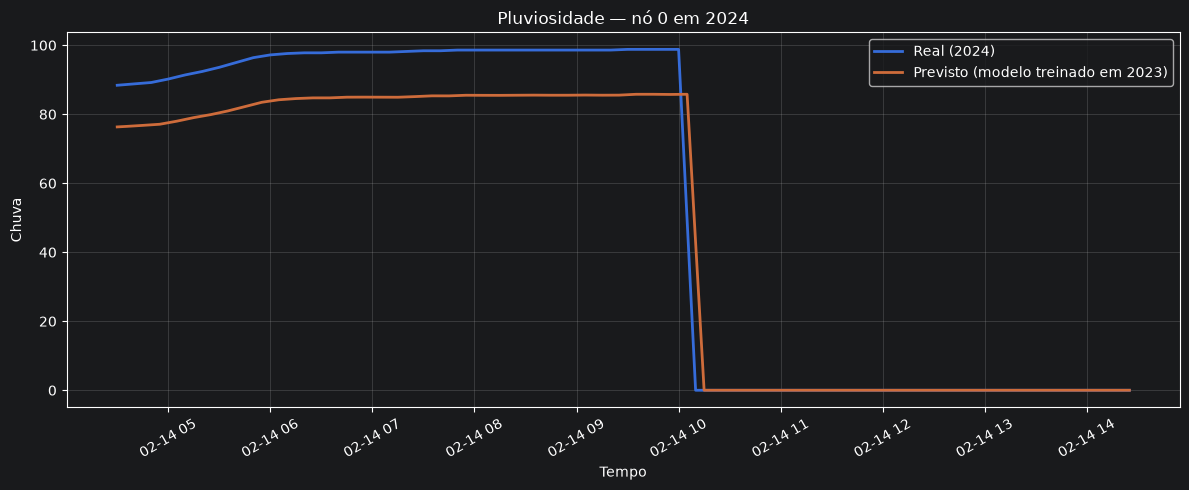

Nó 0 | Pluviosidade | MAE = 0.437392 | RMSE = 1.363260


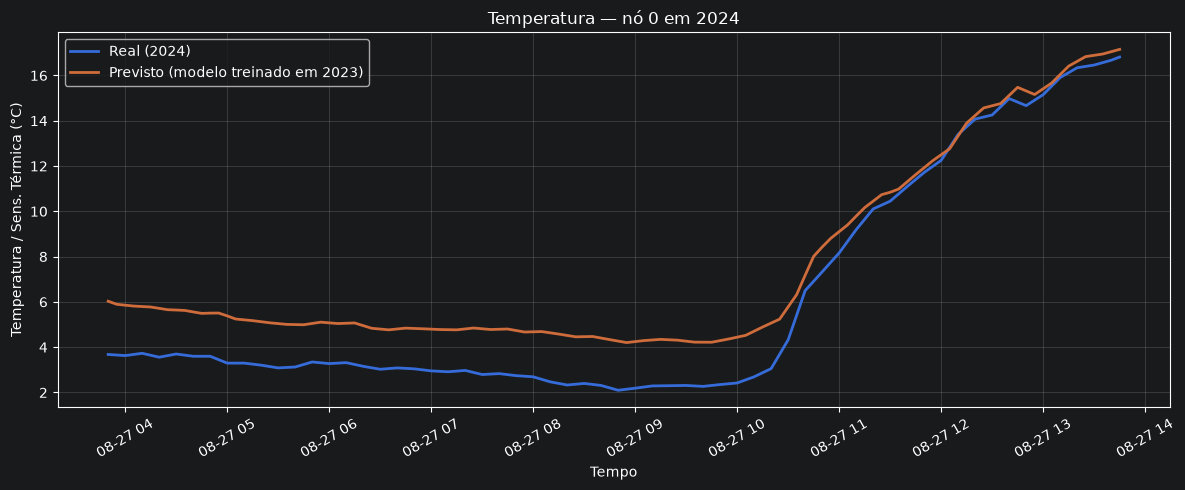

Nó 0 | Temperatura | MAE = 0.262310 | RMSE = 0.367987


In [18]:
def plotar_no_especifico(preds_all, trues_all, timestamps_2024, node_id, nome_variavel, ylabel, criterio_janela="pico_real", window=120):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]
    half_window = window // 2

    if criterio_janela == "pico_real":
        idx_central = int(np.argmax(trues_no))
    else:
        idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))

    start = max(0, idx_central - half_window)
    end = min(len(trues_no), idx_central + half_window)
    tempo_2024 = np.array(timestamps_2024[1:])

    mae = float(np.mean(np.abs(preds_no - trues_no)))
    rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

    plt.figure(figsize=(12, 5))
    plt.plot(tempo_2024[start:end], trues_no[start:end], linewidth=2, label="Real (2024)")
    plt.plot(tempo_2024[start:end], preds_no[start:end], linewidth=2, label="Previsto (modelo treinado em 2023)")
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — nó {node_id} em 2024")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"Nó {node_id} | {nome_variavel} | MAE = {mae:.6f} | RMSE = {rmse:.6f}")

# exemplo:
plotar_no_especifico(preds_chuva_all, trues_chuva_all, timestamps_2024, node_id=0, nome_variavel="Pluviosidade", ylabel="Chuva")
plotar_no_especifico(preds_temp_all, trues_temp_all, timestamps_2024, node_id=0, nome_variavel="Temperatura", ylabel="Temperatura / Sens. Térmica (°C)", criterio_janela="maior_desvio_media")


In [19]:
def obter_indice_no(node_ref, nodes_lista=nodes_lista):
    node_ref_str = str(node_ref)
    nodes_str = [str(n) for n in nodes_lista]

    if node_ref_str in nodes_str:
        return nodes_str.index(node_ref_str)

    if isinstance(node_ref, int) and 0 <= node_ref < len(nodes_lista):
        return node_ref

    raise KeyError(f"Nó {node_ref} não encontrado em nodes_lista.")


def plotar_no_mes(
    preds_all,
    trues_all,
    timestamps,
    node_ref,
    nome_variavel,
    ylabel,
    ano=2024,
    mes=1,
    titulo_real="Referência do experimento cego (média simples dos vizinhos)",
    titulo_prev="Previsto pelo modelo"
):
    node_idx = obter_indice_no(node_ref)
    node_label = G.nodes[str(nodes_lista[node_idx])].get("label", "")

    preds_no = preds_all[:, node_idx]
    trues_no = trues_all[:, node_idx]
    tempo = pd.to_datetime(timestamps[1:])

    mask = (tempo.year == ano) & (tempo.month == mes)
    tempo_mes = tempo[mask]
    preds_mes = preds_no[mask]
    trues_mes = trues_no[mask]

    print(f"Nó {node_ref} ({node_label}) | pontos encontrados em {mes:02d}/{ano}: {len(tempo_mes)}")

    if len(tempo_mes) == 0:
        print("Nenhum dado encontrado.")
        return

    mae = float(np.mean(np.abs(preds_mes - trues_mes)))
    rmse = float(np.sqrt(np.mean((preds_mes - trues_mes) ** 2)))

    plt.figure(figsize=(15, 5))
    plt.plot(tempo_mes, trues_mes, linewidth=2, label=titulo_real)
    plt.plot(tempo_mes, preds_mes, linewidth=2, linestyle="--", label=titulo_prev)
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — Nó {node_ref} ({node_label}) — {mes:02d}/{ano}")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"MAE  = {mae:.6f}")
    print(f"RMSE = {rmse:.6f}")


def plotar_nos_cegos_janeiro(
    nos_cegos=("33", "34", "35"),
    ano=2024,
    mes=1
):
    for node_ref in nos_cegos:
        plotar_no_mes(
            preds_all=preds_chuva_all,
            trues_all=trues_chuva_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Pluviosidade",
            ylabel="Chuva (mm)",
            ano=ano,
            mes=mes
        )
        plotar_no_mes(
            preds_all=preds_temp_all,
            trues_all=trues_temp_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Temperatura",
            ylabel="Temperatura / Sens. Térmica (°C)",
            ano=ano,
            mes=mes
        )


Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 8927


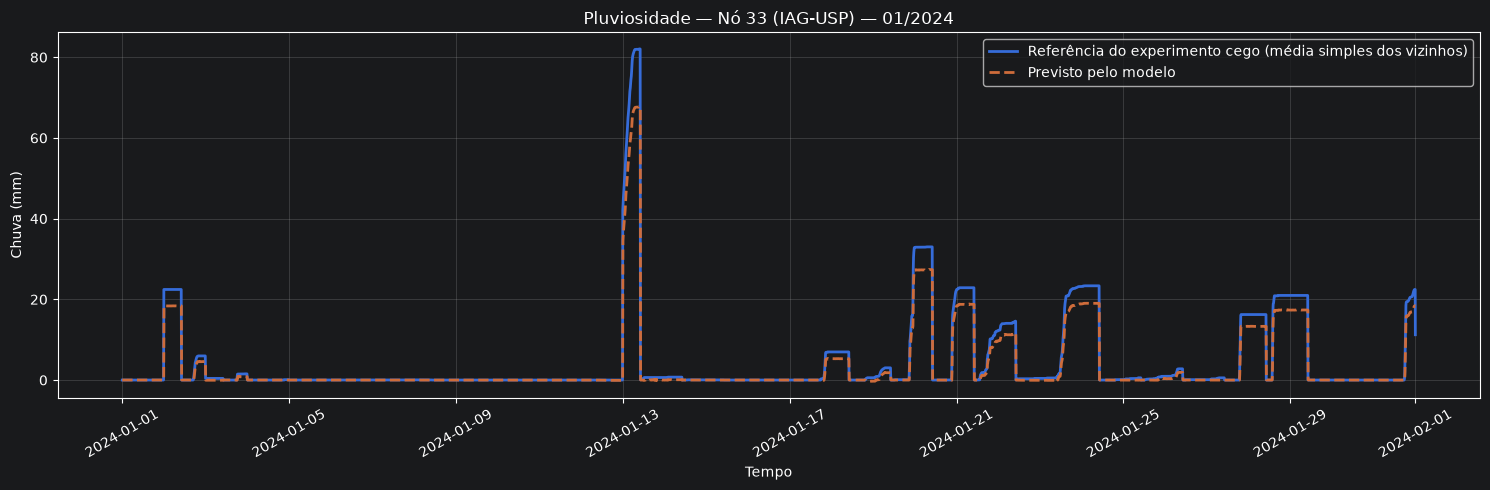

MAE  = 0.937945
RMSE = 2.278085
Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 8927


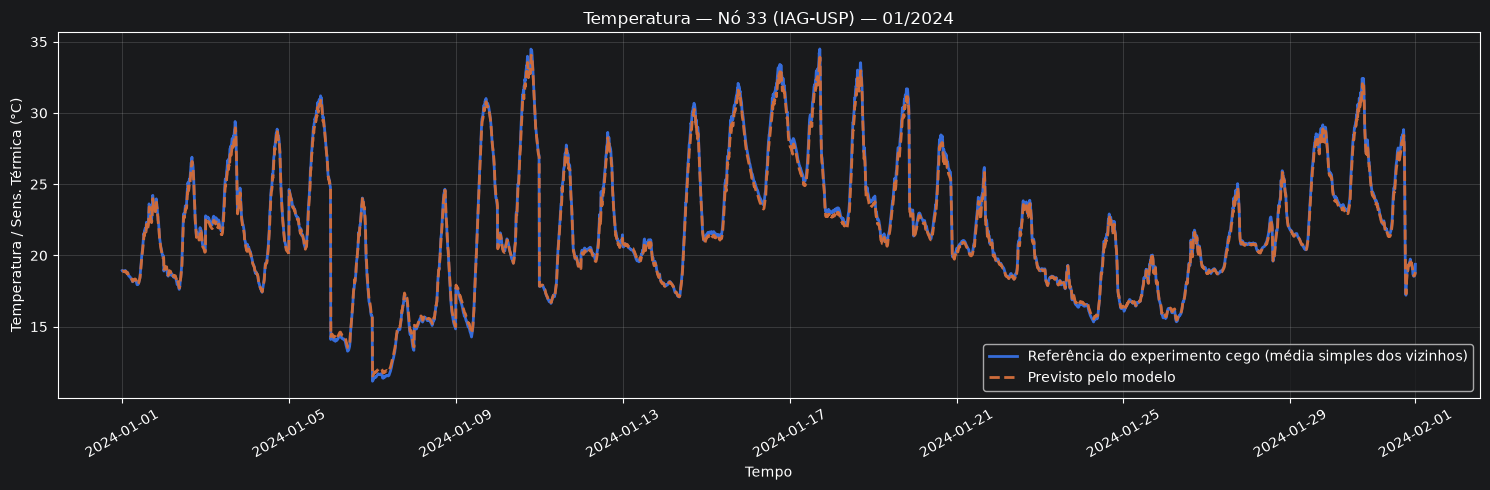

MAE  = 0.209571
RMSE = 0.289642
Nó 34 (INMET - Mirante de Santana) | pontos encontrados em 01/2024: 8927


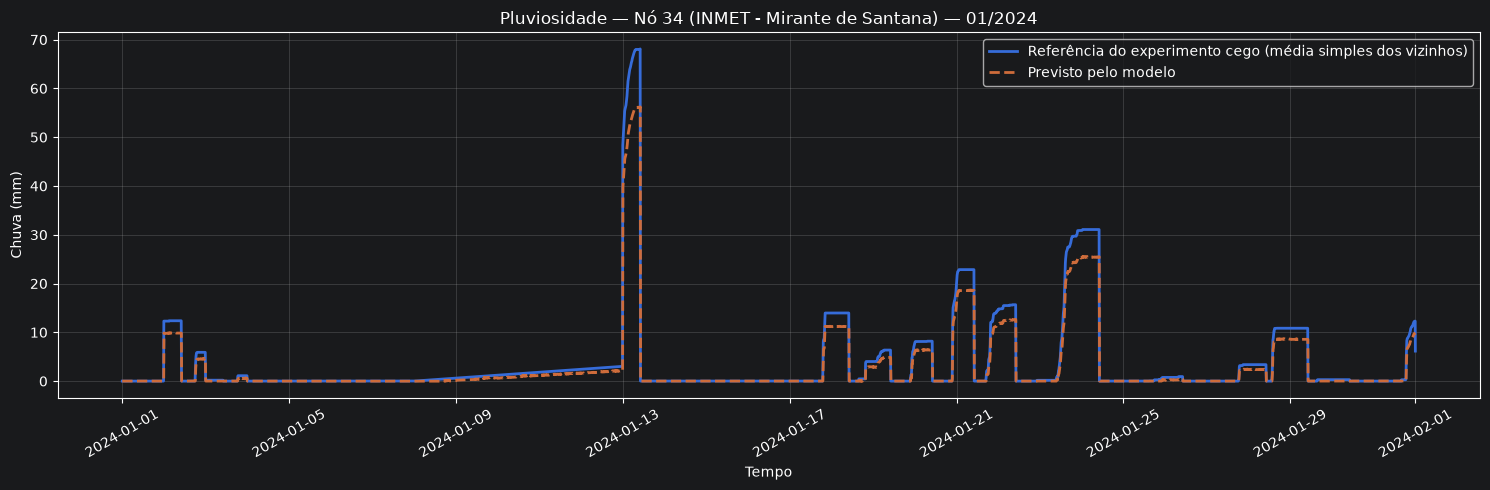

MAE  = 0.844890
RMSE = 1.996417
Nó 34 (INMET - Mirante de Santana) | pontos encontrados em 01/2024: 8927


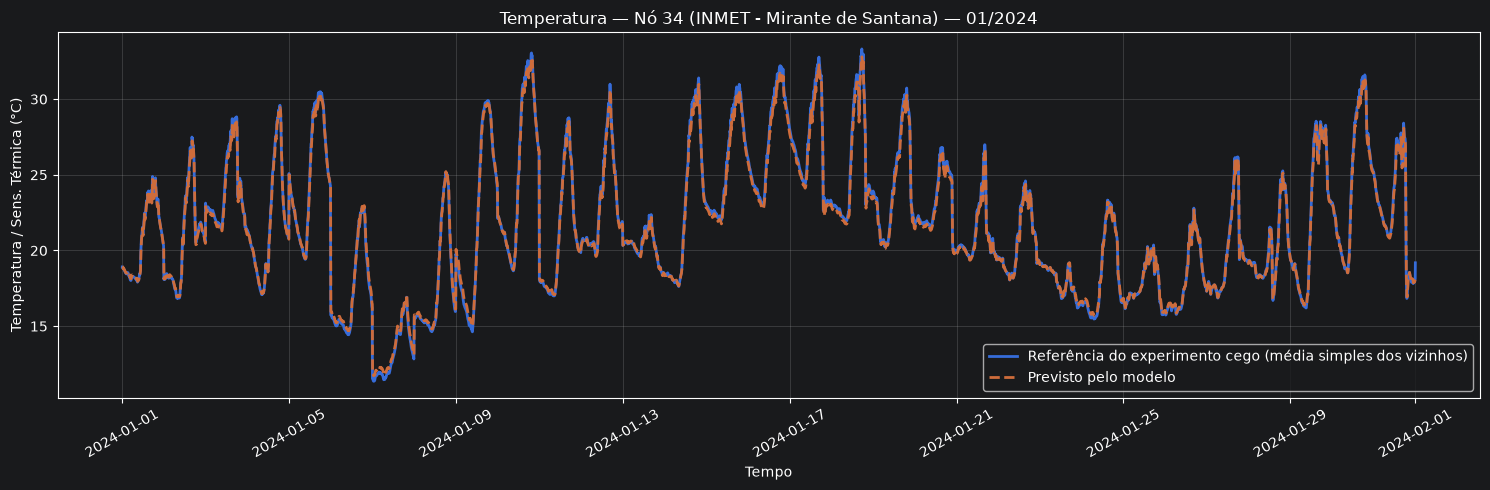

MAE  = 0.196535
RMSE = 0.275875
Nó 35 (INMET - Convencional) | pontos encontrados em 01/2024: 8927


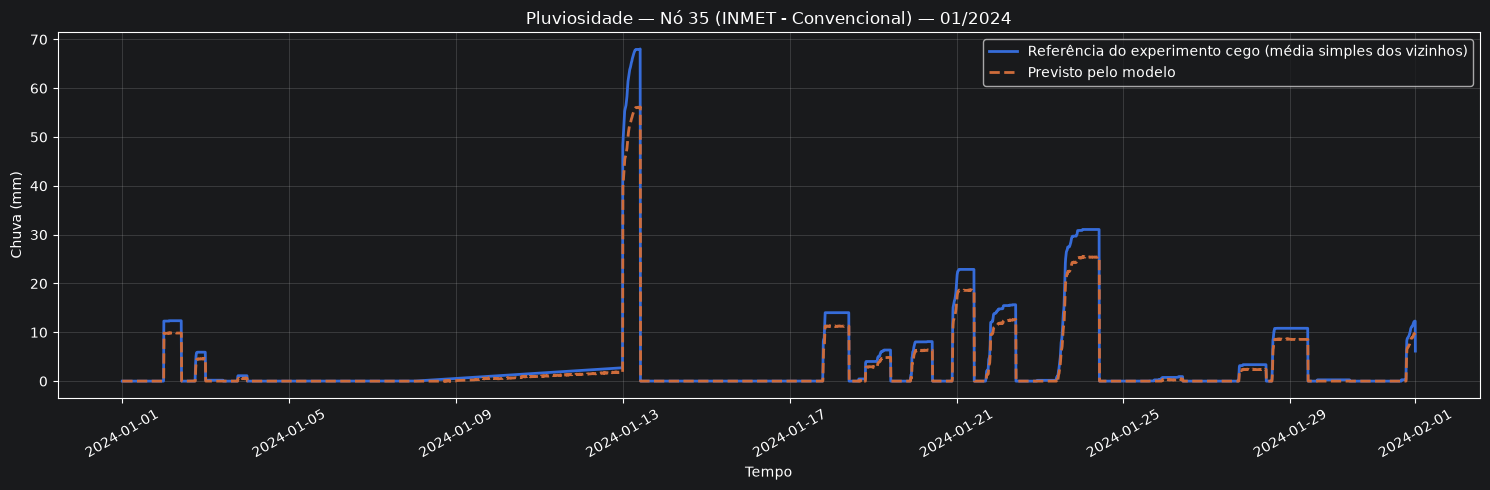

MAE  = 0.842810
RMSE = 1.996243
Nó 35 (INMET - Convencional) | pontos encontrados em 01/2024: 8927


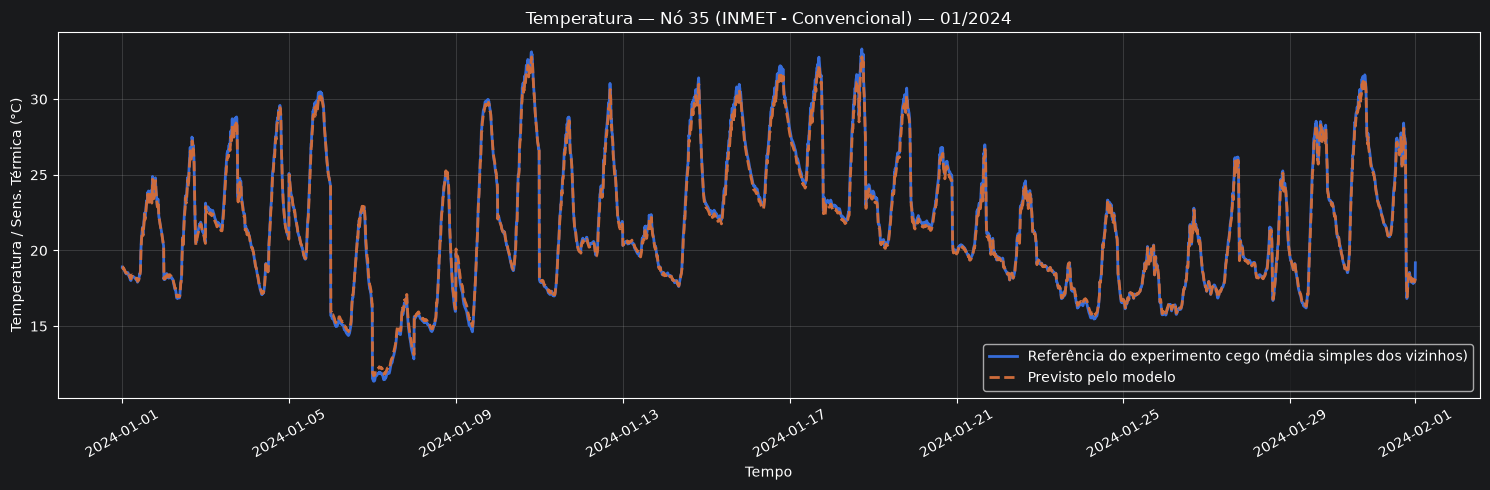

MAE  = 0.196798
RMSE = 0.276371


In [20]:
plotar_nos_cegos_janeiro()


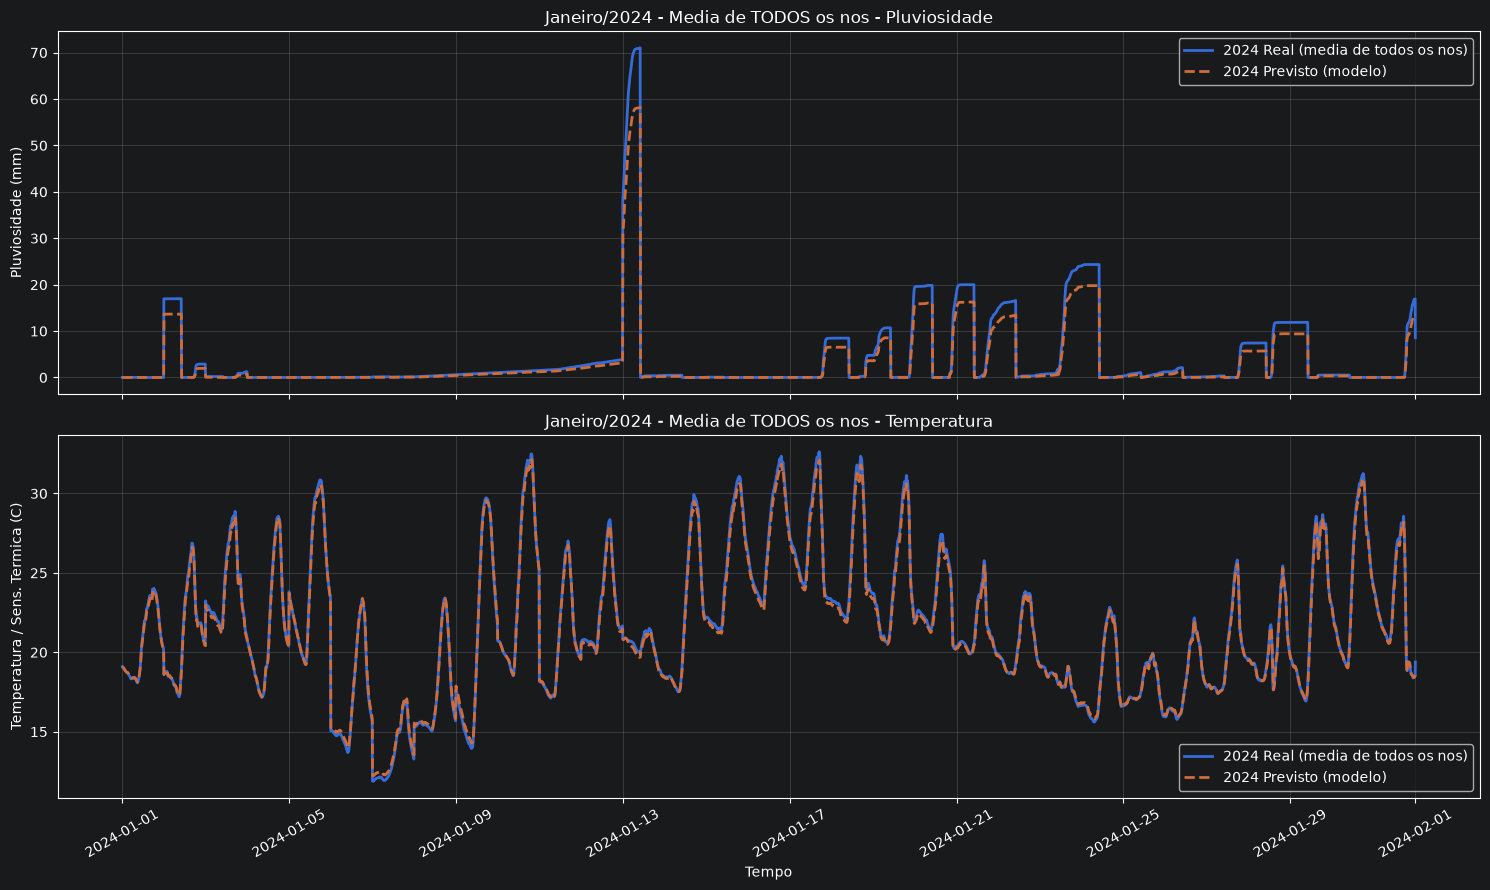


Metricas - Media de TODOS os nos em janeiro/2024
Pluviosidade | MAE = 0.847240 | RMSE = 1.985966
Temperatura  | MAE = 0.192852 | RMSE = 0.258180


In [21]:
def plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all,
    trues_chuva_all,
    preds_temp_all,
    trues_temp_all,
    timestamps_2024
):
    tempo = pd.to_datetime(timestamps_2024[1:])
    mask_jan_2024 = (tempo.year == 2024) & (tempo.month == 1)

    if mask_jan_2024.sum() == 0:
        print("Nenhum ponto encontrado para janeiro de 2024.")
        return

    tempo_jan = tempo[mask_jan_2024]

    media_real_chuva = trues_chuva_all.mean(axis=1)[mask_jan_2024]
    media_prev_chuva = preds_chuva_all.mean(axis=1)[mask_jan_2024]

    media_real_temp = trues_temp_all.mean(axis=1)[mask_jan_2024]
    media_prev_temp = preds_temp_all.mean(axis=1)[mask_jan_2024]

    mae_chuva = float(np.mean(np.abs(media_prev_chuva - media_real_chuva)))
    rmse_chuva = float(np.sqrt(np.mean((media_prev_chuva - media_real_chuva) ** 2)))

    mae_temp = float(np.mean(np.abs(media_prev_temp - media_real_temp)))
    rmse_temp = float(np.sqrt(np.mean((media_prev_temp - media_real_temp) ** 2)))

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

    axes[0].plot(tempo_jan, media_real_chuva, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[0].plot(tempo_jan, media_prev_chuva, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[0].set_ylabel("Pluviosidade (mm)")
    axes[0].set_title("Janeiro/2024 - Media de TODOS os nos - Pluviosidade")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(tempo_jan, media_real_temp, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[1].plot(tempo_jan, media_prev_temp, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[1].set_xlabel("Tempo")
    axes[1].set_ylabel("Temperatura / Sens. Termica (C)")
    axes[1].set_title("Janeiro/2024 - Media de TODOS os nos - Temperatura")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    plt.close()

    print("\nMetricas - Media de TODOS os nos em janeiro/2024")
    print(f"Pluviosidade | MAE = {mae_chuva:.6f} | RMSE = {rmse_chuva:.6f}")
    print(f"Temperatura  | MAE = {mae_temp:.6f} | RMSE = {rmse_temp:.6f}")


plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all=preds_chuva_all,
    trues_chuva_all=trues_chuva_all,
    preds_temp_all=preds_temp_all,
    trues_temp_all=trues_temp_all,
    timestamps_2024=timestamps_2024
)


## Mudança 3 — Identificação de anomalias

Duas regras complementares aplicadas às previsões $\hat{x}_{t+h}$ e aos erros
de previsão:

- **Regra 1 — Limiar meteorológico previsto (alerta antecipado).**
  Pré-computamos $\tau_{i,m,k}$ = percentil 95 por estação $i$, mês $m$ e
  variável $k$. Dispara alerta quando $\hat{x}_{i,k} > \tau_{i,m,k}$.
  Uma **janela anti-ruído** ($W_{alert}=3$) só confirma o alerta após 3
  ativações consecutivas, evitando alarmes falsos por *spikes* de sensor.

- **Regra 2 — Anomaly Score multivariado (distância de Mahalanobis).**
  $AS_{i,t+h} = \sqrt{e^\top \Sigma_i^{-1} e}$, com
  $e = x_{i,t+h} - \hat{x}_{i,t+h}$ (erro após observação) e $\Sigma_i$ a
  covariância histórica das variáveis na estação $i$.


In [22]:
N_NODES = len(nodes_lista)
N_FEATS = X_2024.shape[2]

FEATURE_NAMES = ["PLU", "Temp", "Umid.Rel.", "Vel.VT"][:N_FEATS]
W_ALERT = 3  # janela anti-ruído: nº de timesteps consecutivos p/ confirmar alerta


# ── Regra 1: limiares por estação, mês e variável ────────────────────────────
def compute_thresholds(X_historical, timestamps, percentile=95):
    """Percentil por (mês, nó, variável). Retorna tau [12, N, F]."""
    X_np = X_historical.detach().cpu().numpy() if torch.is_tensor(X_historical) else np.asarray(X_historical)
    N, Fd = X_np.shape[1], X_np.shape[2]
    months = np.array([t.month for t in pd.to_datetime(list(timestamps))])
    tau = np.zeros((12, N, Fd), dtype=np.float64)
    for m in range(12):
        mask = months == (m + 1)
        if mask.sum() == 0:
            tau[m] = np.percentile(X_np, percentile, axis=0)  # fallback global
        else:
            tau[m] = np.percentile(X_np[mask], percentile, axis=0)
    return tau


def rule1_alert(X_hat, tau, month):
    """X_hat [N, F]; month 1..12. Retorna máscara booleana [N, F]."""
    return X_hat > tau[month - 1]


def aplicar_janela_antiruido(alert_series, w_alert=W_ALERT):
    """alert_series: array booleano [T, N, F]. Confirma alerta apenas após
    w_alert ativações consecutivas da Regra 1. Retorna [T, N, F] booleano."""
    alert_series = np.asarray(alert_series, dtype=bool)
    T = alert_series.shape[0]
    confirmado = np.zeros_like(alert_series)
    run = np.zeros(alert_series.shape[1:], dtype=int)
    for t in range(T):
        run = np.where(alert_series[t], run + 1, 0)
        confirmado[t] = run >= w_alert
    return confirmado


# ── Regra 2: anomaly score (Mahalanobis) ─────────────────────────────────────
def compute_sigma_inv(X_historical):
    """Covariância histórica por estação. Retorna sigma_inv [N, F, F]."""
    X_np = X_historical.detach().cpu().numpy() if torch.is_tensor(X_historical) else np.asarray(X_historical)
    N, Fd = X_np.shape[1], X_np.shape[2]
    sigma_inv = np.zeros((N, Fd, Fd), dtype=np.float64)
    for i in range(N):
        xi = X_np[:, i, :]
        if Fd == 1:
            var = np.var(xi[:, 0])
            sigma_inv[i] = np.array([[1.0 / var]]) if var > 1e-12 else np.array([[0.0]])
        else:
            cov = np.cov(xi.T)
            sigma_inv[i] = np.linalg.pinv(cov)
    return sigma_inv


def compute_anomaly_score(x_real, x_hat, sigma_inv):
    """x_real, x_hat: [N, F]; sigma_inv: [N, F, F]. Retorna AS [N]."""
    e = x_real - x_hat
    return torch.einsum("nf,nfg,ng->n", e, sigma_inv, e).clamp(min=0).sqrt()


# ── Cálculo dos artefatos de anomalia ────────────────────────────────────────
# Limiares e covariâncias estimados sobre o histórico (2023).
tau = compute_thresholds(X_2023, timestamps_2023, percentile=95)
sigma_inv = compute_sigma_inv(X_2023)
print("tau:", tau.shape, "| sigma_inv:", sigma_inv.shape)

# Previsões multivariadas no conjunto de teste (2024): usamos os dois modelos
# treinados (PLU e Temp). Demais variáveis assumem persistência da entrada.
modelo.eval(); modelo_temp.eval()
sigma_inv_t = torch.tensor(sigma_inv, dtype=torch.float32, device=DEVICE)

X_hat_mv = []        # previsões multivariadas [T-1, N, F]
with torch.no_grad():
    for i in range(len(X_test)):
        xin = X_test[i]
        pred_plu = modelo(g_pyg, xin)
        pred_temp = modelo_temp(g_pyg, xin)
        xh = xin.clone()
        xh[:, TARGET_IDX_PLU] = pred_plu
        xh[:, TARGET_IDX_TEMP] = pred_temp
        X_hat_mv.append(xh)
X_hat_mv = torch.stack(X_hat_mv)  # [T-1, N, F]

# Real correspondente em t+1.
X_real_next = X_2024[1:]  # [T-1, N, F]

# Regra 1 sobre as previsões (por mês de cada timestep).
meses_test = np.array([t.month for t in pd.to_datetime(list(timestamps_2024))[1:]])
alert_raw = np.zeros((len(X_hat_mv), N_NODES, N_FEATS), dtype=bool)
xhat_np = X_hat_mv.detach().cpu().numpy()
for t in range(len(X_hat_mv)):
    alert_raw[t] = rule1_alert(xhat_np[t], tau, int(meses_test[t]))
alert_confirmado = aplicar_janela_antiruido(alert_raw, W_ALERT)
print(f"Regra 1: {alert_raw.sum()} ativações brutas -> "
      f"{alert_confirmado.sum()} confirmadas (janela W={W_ALERT}).")

# Regra 2: anomaly score por timestep e nó.
anomaly_scores = np.zeros((len(X_hat_mv), N_NODES), dtype=np.float64)
with torch.no_grad():
    for t in range(len(X_hat_mv)):
        anomaly_scores[t] = compute_anomaly_score(
            X_real_next[t], X_hat_mv[t], sigma_inv_t
        ).detach().cpu().numpy()
print("anomaly_scores:", anomaly_scores.shape,
      "| AS médio:", float(np.nanmean(anomaly_scores)))

# Tabela consolidada de alertas (Regra 1 confirmada).
linhas_alerta = []
tempo_test = pd.to_datetime(list(timestamps_2024))[1:]
ts_idx, no_idx, ft_idx = np.where(alert_confirmado)
for t, n, fdim in zip(ts_idx, no_idx, ft_idx):
    linhas_alerta.append({
        "Estacao": str(nodes_lista[n]),
        "Variavel": FEATURE_NAMES[fdim],
        "Tipo": "Regra 1 (limiar previsto)",
        "AS_Score": float(anomaly_scores[t, n]),
        "Timestamp": tempo_test[t],
    })
df_alertas = pd.DataFrame(linhas_alerta)
print(f"\nTotal de alertas confirmados: {len(df_alertas)}")
if len(df_alertas):
    display(df_alertas.sort_values("AS_Score", ascending=False).head(15))


tau: (12, 35, 4) | sigma_inv: (35, 4, 4)
Regra 1: 1723622 ativações brutas -> 1608500 confirmadas (janela W=3).
anomaly_scores: (105291, 35) | AS médio: 0.3545048197827172

Total de alertas confirmados: 1608500


,Estacao,Variavel,Tipo,AS_Score,Timestamp
132237,24,Vel.VT,Regra 1 (limiar previsto),20.997637,2024-01-31 18:20:00
53059,28,PLU,Regra 1 (limiar previsto),14.070289,2024-01-13 10:10:00
1549895,24,Vel.VT,Regra 1 (limiar previsto),13.248006,2024-12-20 20:00:00
1549879,24,Vel.VT,Regra 1 (limiar previsto),13.247409,2024-12-20 19:55:00
946098,24,Vel.VT,Regra 1 (limiar previsto),11.651317,2024-08-01 18:10:00
946064,24,Vel.VT,Regra 1 (limiar previsto),11.649648,2024-08-01 18:05:00
1344828,24,Vel.VT,Regra 1 (limiar previsto),11.619830,2024-10-25 15:55:00
1344851,24,Vel.VT,Regra 1 (limiar previsto),11.619637,2024-10-25 16:00:00
1343806,24,Vel.VT,Regra 1 (limiar previsto),11.313042,2024-10-25 11:35:00
1343821,24,Vel.VT,Regra 1 (limiar previsto),11.313014,2024-10-25 11:40:00


## Métricas: baseline (média simples dos vizinhos) vs FP + GraphSAGE (nós cegos)

Compara, nos nós cegos, a estimativa antiga (média simples dos vizinhos) com a
nova (Feature Propagation + GraphSAGE), em MAE/RMSE por variável.


In [23]:
def mae_rmse(real, est):
    real = np.asarray(real); est = np.asarray(est)
    mae = float(np.mean(np.abs(est - real)))
    rmse = float(np.sqrt(np.mean((est - real) ** 2)))
    return mae, rmse

linhas = []
X2024_np = X_2024.detach().cpu().numpy()
X2024_base_np = X_2024_baseline.detach().cpu().numpy()
for j in blind_idx:
    nome = str(nodes_lista[j])
    for fdim, fname in enumerate(FEATURE_NAMES):
        # "real" de referência para nós cegos = valor FP (não há observação direta);
        # comparamos a entrada baseline com a entrada FP por variável.
        mae_b, rmse_b = mae_rmse(X2024_np[:, j, fdim], X2024_base_np[:, j, fdim])
        linhas.append({
            "No": nome, "Variavel": fname,
            "MAE_baseline_vs_FP": mae_b, "RMSE_baseline_vs_FP": rmse_b,
        })
df_metricas_cegos = pd.DataFrame(linhas)
print("Diferença entre inicialização baseline e Feature Propagation (nós cegos):")
display(df_metricas_cegos)

# Métrica global de previsão (FP + GraphSAGE) por variável no teste.
resumo_pred = pd.DataFrame([
    {"Variavel": "Pluviosidade",
     "MAE": float(df_resultados_chuva["mae"].mean()),
     "RMSE": float(df_resultados_chuva["rmse"].mean())},
    {"Variavel": "Temperatura",
     "MAE": float(df_resultados_temp["mae"].mean()),
     "RMSE": float(df_resultados_temp["rmse"].mean())},
])
print("\nMétricas médias de previsão (FP + GraphSAGE) no teste 2024:")
display(resumo_pred)


Diferença entre inicialização baseline e Feature Propagation (nós cegos):


,No,Variavel,MAE_baseline_vs_FP,RMSE_baseline_vs_FP
0,33,PLU,0.100486,0.388558
1,33,Temp,0.063061,0.109597
2,33,Umid.Rel.,0.767735,1.088253
3,33,Vel.VT,0.062859,0.083244
4,34,PLU,0.917890,2.565537
5,34,Temp,4.063535,4.289465
6,34,Umid.Rel.,13.562487,14.596208
7,34,Vel.VT,0.379998,0.453764
8,35,PLU,0.630531,2.089903
9,35,Temp,4.964291,5.078786



Métricas médias de previsão (FP + GraphSAGE) no teste 2024:


,Variavel,MAE,RMSE
0,Pluviosidade,0.446642,1.314528
1,Temperatura,0.215090,0.308282


## Exportação de artefatos para o dashboard

Salva em `artifacts/` tudo o que o `dashboard.py` (Streamlit) precisa para
simular o monitoramento: pesos dos modelos, limiares, covariâncias inversas,
estrutura do grafo, e os tensores/previsões de teste.


In [24]:
import pickle

os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# 1) Pesos dos modelos.
torch.save(modelo.state_dict(), os.path.join(ARTIFACTS_DIR, "model_plu.pt"))
torch.save(modelo_temp.state_dict(), os.path.join(ARTIFACTS_DIR, "model_temp.pt"))

# 2) Limiares tau [12, N, F].
with open(os.path.join(ARTIFACTS_DIR, "tau.pkl"), "wb") as f:
    pickle.dump(tau, f)

# 3) Inversas de covariância [N, F, F].
with open(os.path.join(ARTIFACTS_DIR, "sigma_inv.pkl"), "wb") as f:
    pickle.dump(sigma_inv, f)

# 4) Estrutura do grafo: edge_index, edge_weight, coords, nomes.
coords = {}
labels = {}
for n in nodes_lista:
    ns = str(n)
    coords[ns] = (float(G.nodes[ns].get("lat", 0.0)), float(G.nodes[ns].get("lon", 0.0)))
    labels[ns] = str(G.nodes[ns].get("label", ns))

graph_data = {
    "edge_index": g_pyg.edge_index.detach().cpu().numpy(),
    "edge_weight": g_pyg.edge_weight.detach().cpu().numpy(),
    "edge_weight_sym": g_pyg.edge_weight_sym.detach().cpu().numpy(),
    "nodes_lista": [str(n) for n in nodes_lista],
    "coords": coords,
    "labels": labels,
    "blind_nodes": sorted(NOS_SEM_DADOS),
    "feature_names": FEATURE_NAMES,
    "target_idx_plu": TARGET_IDX_PLU,
    "target_idx_temp": TARGET_IDX_TEMP,
    "model_h_feats": 32,
}
with open(os.path.join(ARTIFACTS_DIR, "graph_data.pkl"), "wb") as f:
    pickle.dump(graph_data, f)

# 5) Tensores de teste + previsões + alertas + score, para simular monitoramento.
X_test_export = {
    "X_2024": X_2024.detach().cpu().numpy(),              # [T, N, F] (com FP)
    "X_2024_baseline": X_2024_baseline.detach().cpu().numpy(),  # baseline média vizinhos
    "timestamps_2024": [pd.Timestamp(t).isoformat() for t in timestamps_2024],
    "X_hat_mv": X_hat_mv.detach().cpu().numpy(),          # previsões [T-1, N, F]
    "X_real_next": X_real_next.detach().cpu().numpy(),    # real em t+1 [T-1, N, F]
    "alert_confirmado": alert_confirmado,                 # [T-1, N, F] bool
    "anomaly_scores": anomaly_scores,                     # [T-1, N]
    "preds_chuva_all": preds_chuva_all,
    "trues_chuva_all": trues_chuva_all,
    "preds_temp_all": preds_temp_all,
    "trues_temp_all": trues_temp_all,
    "df_alertas": df_alertas,
    "df_resultados_chuva": df_resultados_chuva,
    "df_resultados_temp": df_resultados_temp,
    "df_metricas_cegos": df_metricas_cegos,
    "resumo_pred": resumo_pred,
}
with open(os.path.join(ARTIFACTS_DIR, "X_test.pkl"), "wb") as f:
    pickle.dump(X_test_export, f)

print("Artefatos salvos em", os.path.abspath(ARTIFACTS_DIR))
for fn in sorted(os.listdir(ARTIFACTS_DIR)):
    print("  -", fn)


Artefatos salvos em /home/viniz0r/backup_GNN_2026-07-07/paper_essenciais/codigo/artifacts
  - X_test.pkl
  - graph_data.pkl
  - model_plu.pt
  - model_temp.pt
  - sigma_inv.pkl
  - tau.pkl
